# Discrete and smeared stringers: integrally stiffened Technion shells (Weller and Singer 1977; Poorveis and Kabir 2006)

How far is a model with discrete stringers from the smeared-stiffener theory
when the stringers are closely spaced? Weller and Singer [1] tested in axial
compression integrally stringer-stiffened 7075-T6 shells with the stringers
outside and give, for each shell, the non-dimensional stringer properties,
the load of the linear smeared-stiffener theory for the simple supports SS3
($w = M_x = N_x = v = 0$) and SS4 ($w = M_x = u = v = 0$) and the test load
(Table 1, p. 723). Poorveis and Kabir [2] analysed one of these shells
(AS-27M2, their case A) and a shell of Shen, Zhou and Chen (case D, shell
AB6 of [6], through [3]) with a geometrically nonlinear Ritz model, with discrete and with
smeared stringers (Table 2, p. 119), and a third shell (case C, shell DUD-8
of [5]) under external pressure and combined loading; the twin shell DUD-10
of [5], buckled under combined loading in the reversed sequence, is added.
The pressure is applied as a dead and as a live (follower) load, and case C
and case D are also studied under combined pressure and axial compression,
with the interaction curves of Shen, Zhou and Chen [3] for DUD-8 and DUD-10. This notebook builds the shells as
`MultiDomain` assemblies with discrete blade stringers and compares with
these values, and with the smeared theory of Block, Card and Mikulas [4]
(equation (15), SS3, membrane pre-buckling state) evaluated for the section of
[1] (which reproduces the SS3 loads of [1]) and for the section of the
discrete model (the reference of the **discreteness gap**).

The AS-27 shells have a Koiter parameter $\theta > 0.64$, chosen by Weller and
Singer to study unstable postbuckling of the skin panels between the
stringers (p. 722); for AS-27M2 Poorveis and Kabir found the discrete value
30 % below the smeared one and attributed it to panel instability (p. 119).

[1] T. Weller and J. Singer, *Experimental studies on the buckling under
axial compression of integrally stringer-stiffened circular cylindrical
shells*, J. Appl. Mech. 44(4), 721-730, 1977, doi:10.1115/1.3424163.

[2] D. Poorveis and M. Z. Kabir, *Buckling of discretely stringer-stiffened
composite cylindrical shells under combined axial compression and external
pressure*, Scientia Iranica 13(2), 113-123, 2006.

[3] H.-S. Shen, P. Zhou and T.-Y. Chen, *Postbuckling analysis of stiffened
cylindrical shells under combined external pressure and axial compression*,
Thin-Walled Struct. 15(1), 43-63, 1993, doi:10.1016/0263-8231(93)90012-Y.

[4] D. L. Block, M. F. Card and M. M. Mikulas, Jr., *Buckling of eccentrically
stiffened orthotropic cylinders*, NASA TN D-2960, 1965,
https://ntrs.nasa.gov/citations/19650021133.

[5] H. Abramovich, T. Weller and J. Singer, *Effect of sequence of combined
loading on buckling of stiffened shells*, Exp. Mech. 28(1), 1-13, 1988,
doi:10.1007/BF02328988.

[6] J. Singer and H. Abramovich, *Vibration techniques for definition of
practical boundary conditions in stiffened shells*, AIAA J. 17(7), 762-769,
1979, doi:10.2514/3.61215.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import blade_cylinder_utils as bu
import stringer_cylinder_utils as su


def pct(value, ref):
    return 100*(value/ref - 1)


def table(header, rows):
    out = ['| ' + ' | '.join(header) + ' |', '|' + '---|'*len(header)]
    out += ['| ' + ' | '.join(str(c) for c in row) + ' |' for row in rows]
    display(Markdown('\n'.join(out)))

def plot_mode(ax, md_, c, skin, R, title, ns, frac=1.):
    x, th, w = bu.skin_w(md_, c, skin, R)
    sel = th <= frac*th.max() + 1e-12
    ax.pcolormesh(np.degrees(th[sel]), x, (w[sel]/np.abs(w).max()).T, cmap='RdBu_r',
                  shading='auto', vmin=-1, vmax=1)
    pos = (np.arange(ns) + 0.5)*2*np.pi/ns
    pos = pos[pos <= th[sel].max()]
    ax.plot(np.degrees(pos), np.zeros_like(pos), 'k.', ms=3)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel(r'$\theta$, deg')

## Shells, geometry and material

Table 1 of [1] (p. 723): skin thickness $h$, $R/h$, $L/R$, $-(e_1/h)$ ($e_1$
negative outside, Fig. 1), $A_1/(bh)$, $I_{11}/(bh^3)$ (about the centroid
of the stringer), $\eta_{t1} = G_1 I_{t1}/(bD)$ with $D = E h^3/(12(1 -
\nu^2))$, Koiter's parameter $\theta = [12(1 - \nu^2)]^{1/4} (b/2\pi)
(Rh)^{-1/2}$ (p. 722), the SS3 and SS4 smeared loads and the test load, in
kg (kilogram-force). $E = 0.75 \times 10^4$ kg/mm$^2$ (p. 724), $\nu = 0.30$
(p. 722). The spacing $b$ follows from $\theta$; $2\pi R/b$ gives the
number of stringers. Units here: mm and kg (force); $\bar{N}$ in kg/mm
(times 9.807 for N/mm). AS-26M1 to AS-26M3 are excluded, as by the authors
(footnote b); the SS4 load of AS-35 is misprinted (460 kg; $2850/0.610 = 4672$
kg from the printed ratio) and not used. [1] gives each stringer by its area
$A_1$, its moment of inertia $I_{11}$ about its own centroidal axis and its
eccentricity $e_1$ (nomenclature and Fig. 1, p. 722). The stringers are
rectangles $t_s \times h_s$ standing on the outer surface of the skin: $h_s =
\sqrt{12 I_{11}/A_1}$, $t_s = A_1/h_s$, and the centroid of the rectangle,
$(h + h_s)/2$ from the middle surface of the skin, reproduces $e_1$ within
0.2 % (table below); the torsion constant of the rectangle reproduces
$I_{t1}$ (see the bfsccylinder implementation of this case for the check).
The blades of the model are these rectangles, from the skin surface to the
tip.

In [2]:
E, NU, KGF = 0.75e4, 0.30, 9.80665
TABLE1 = {
    'AS-27M1': (0.195, 618, 0.648, 3.86, 0.760, 2.860, 23.50, 0.807, 4190, 3600),
    'AS-27M2': (0.204, 591, 0.652, 3.67, 0.717, 2.400, 19.84, 0.789, 4210, 3300),
    'AS-27M3': (0.202, 597, 0.650, 3.72, 0.729, 2.520, 20.83, 0.793, 4240, 3920),
    'AS-34': (0.254, 472, 1.080, 2.97, 0.533, 1.080, 5.75, 0.470, 3430, 2800),
    'AS-35': (0.250, 480, 1.080, 3.04, 0.549, 1.180, 6.11, 0.474, 3390, 2850),
}
# Poorveis and Kabir (2006), Table 1 (p. 119): L, R, h, n_s, A1/(b1 h), e1/h, I1/(b h^3), G1 J1/(b D)
# and Table 2: test, smeared, discrete (kg/mm)
POORVEIS_D = (130.00, 120.10, 0.254, 85, 0.590, 3.420, 1.680, 6.563)
POORVEIS_T2 = {'A': (4.356, 6.110, 4.250), 'D': (5.334, 5.370, 5.450)}
k4 = (12*(1 - NU**2))**0.25
G = E/(2*(1 + NU))


def shell(h, R, L, ns, A, I, e, J, P3=None, Pe=None):
    d = dict(h=h, R=R, L=L, ns=ns, b=2*np.pi*R/ns, A=A, I=I, e=e, J=J, P3=P3, Pe=Pe)
    d['hs'] = np.sqrt(12*I/A)
    d['ts'] = A/d['hs']
    # the plate strip of the model is the rectangle h_s on the skin surface
    d['Hs'] = d['hs']
    d['Jplate'] = d['Hs']*d['ts']**3/3
    return d


def plate_section(d):
    # area, eccentricity and moment of inertia about the middle surface of the skin
    # of the plate strip t_s x H_s on the skin surface
    A, z = d['ts']*d['Hs'], (d['h'] + d['Hs'])/2
    return (A, z, d['ts']*d['Hs']**3/12 + A*z**2)


shells = {}
rows = []
for s, (h, Rh, LR, e, Ab, Ib, eta, theta, P3, Pe) in TABLE1.items():
    R = Rh*h
    ns = int(round(2*np.pi*R/(theta*2*np.pi*np.sqrt(R*h)/k4)))
    b = 2*np.pi*R/ns
    D = E*h**3/(12*(1 - NU**2))
    shells[s] = shell(h, R, LR*R, ns, Ab*b*h, Ib*b*h**3, e*h, eta*b*D/G, P3, Pe)
L, R, h, ns, Ab, e, Ib, eta = POORVEIS_D
b = 2*np.pi*R/ns
shells['D'] = shell(h, R, L, ns, Ab*b*h, Ib*b*h**3, e*h, eta*b*E*h**3/(12*(1 - NU**2))/G)
for s, d in shells.items():
    rows.append([s, '%.3f' % d['h'], '%.2f' % d['R'], '%.2f' % d['L'], d['ns'], '%.3f' % d['ts'],
                 '%.3f' % d['hs'], '%.4f (%.4f)' % ((d['h'] + d['hs'])/2, d['e']),
                 '%.3f' % d['J'], '%.2f' % (d['J']/d['Jplate'])])
table(['shell', 'h, mm', 'R, mm', 'L, mm', 'n_s', 't_s, mm', 'h_s, mm', '(h + h_s)/2 (e_1), mm',
       'I_t1, mm^4', 'I_t1/J_plate'], rows)

| shell | h, mm | R, mm | L, mm | n_s | t_s, mm | h_s, mm | (h + h_s)/2 (e_1), mm | I_t1, mm^4 | I_t1/J_plate |
|---|---|---|---|---|---|---|---|---|---|
| AS-27M1 | 0.195 | 120.51 | 78.09 | 56 | 1.529 | 1.310 | 0.7527 (0.7527) | 0.561 | 0.36 |
| AS-27M2 | 0.204 | 120.56 | 78.61 | 56 | 1.530 | 1.293 | 0.7485 (0.7487) | 0.542 | 0.35 |
| AS-27M3 | 0.202 | 120.59 | 78.39 | 56 | 1.532 | 1.301 | 0.7515 (0.7514) | 0.553 | 0.36 |
| AS-34 | 0.254 | 119.89 | 129.48 | 84 | 0.969 | 1.252 | 0.7532 (0.7544) | 0.201 | 0.53 |
| AS-35 | 0.250 | 120.00 | 129.60 | 84 | 0.970 | 1.270 | 0.7598 (0.7600) | 0.204 | 0.53 |
| D | 0.254 | 120.10 | 130.00 | 85 | 0.896 | 1.485 | 0.8694 (0.8687) | 0.227 | 0.64 |

## Smeared-stiffener theory

Equation (15) of [4] (`su.smeared_ss`, minimum over $m \le 12$, $n \le 60$)
with the section of [1] reproduces the SS3 loads of [1]. The discrete model
represents a stringer by the plate strip $t_s \times h_s$ standing on the
outer surface of the skin, the rectangle above; as a smeared section this
strip has $A = t_s h_s$, $\bar{z} = (h + h_s)/2$ and $I_o = t_s h_s^3/12 + A
\bar{z}^2$ about the middle surface of the skin, the section of [1] up to the
rounding of $e_1$ (equation (15) for the two agrees within 0.05 %), and the
twisting stiffness of a Kirchhoff plate strip $4 D_{66} h_s = G h_s t_s^3/3$
("plate J"), 1.6 to 2.9 times $G I_{t1}$ for these squat stringers (last
column above). The main model scales $D_{66}$ of the blades so that $4 D_{66}
h_s = G I_{t1}$ ("matched J"); both are run.

In [3]:
rows = []
for s, d in shells.items():
    Wsec = (d['A'], d['e'], d['I'] + d['A']*d['e']**2)
    Psec = plate_section(d)
    d['sm_W'] = su.smeared_ss(d['R'], d['L'], d['h'], E, NU, d['b'], *Wsec, d['J'])
    d['sm'] = {'matched': su.smeared_ss(d['R'], d['L'], d['h'], E, NU, d['b'], *Psec, d['J']),
               'plate': su.smeared_ss(d['R'], d['L'], d['h'], E, NU, d['b'], *Psec, d['Jplate'])}
    N3 = d['P3']/(2*np.pi*d['R']) if d['P3'] else None
    rows.append([s, '-' if N3 is None else '%.3f' % N3,
                 '%.3f %s' % d['sm_W'] + ('' if N3 is None else ', %+.2f %%' % pct(d['sm_W'][0], N3)),
                 '%.3f %s' % d['sm']['matched'], '%.3f %s' % d['sm']['plate']])
table(['shell', 'SS3 of [1], kg/mm', 'Eq. (15), section of [1]', 'Eq. (15), strip, matched J',
       'Eq. (15), strip, plate J'], rows)

| shell | SS3 of [1], kg/mm | Eq. (15), section of [1] | Eq. (15), strip, matched J | Eq. (15), strip, plate J |
|---|---|---|---|---|
| AS-27M1 | 5.534 | 5.540 (1, 13), +0.11 % | 5.540 (1, 13) | 7.771 (1, 11) |
| AS-27M2 | 5.558 | 5.557 (1, 13), -0.01 % | 5.556 (1, 13) | 7.797 (1, 11) |
| AS-27M3 | 5.596 | 5.589 (1, 13), -0.11 % | 5.590 (1, 13) | 7.831 (1, 11) |
| AS-34 | 4.553 | 4.547 (1, 11), -0.14 % | 4.545 (1, 11) | 5.030 (1, 11) |
| AS-35 | 4.496 | 4.491 (1, 11), -0.11 % | 4.491 (1, 11) | 4.984 (1, 11) |
| D | - | 5.018 (1, 11) | 5.020 (1, 11) | 5.371 (1, 11) |

## Model with discrete stringers

`su.buckling_membrane`: the assembly of `bu.build_cylinder`, curved skin
panels `cylshell_clpt_sanders` between the stringers and one `plate_clpt_gl`
blade per stringer (`'SSycte'` and `'BFycte'` connections); the half cylinder
between two symmetry planes through the middle of a bay for an even number of
stringers, the whole cylinder for case D (85 stringers). SS3 ends ($v = w =
0$ on skin and blades, $u$ free, one point with $u = 0$), membrane
pre-buckling state of a uniform axial strain in skin and blades, as in the
smeared theory; ten eigenvalues, the lowest positive one is critical, its
$(m, n)$ from the normal displacement of the skin (`bu.classify`).

## Convergence

Terms $m_x$ along $x$ (skin and blades), $n_y$ across a skin bay and $n_b$
across a blade, matched $J$.

In [4]:
LEVELS = [(12, 6, 4), (16, 8, 4), (20, 10, 5)]
t0 = time.time()
rows = []
for s in ('AS-27M2', 'AS-34'):
    d = shells[s]
    prev = None
    for lev in LEVELS:
        N, modes, N1, md_, skin, ndof, dt = su.buckling_membrane(
            d['R'], d['h'], d['L'], E, NU, d['ts'], d['Hs'], 'external', 'SS', d['ns'], *lev,
            D66_factor=d['J']/d['Jplate'])
        rows.append([s, lev, ndof, '%.1f' % dt, '%.4f' % N, '(%d, %d)' % modes[0][1:3],
                     '' if prev is None else '%+.2f %%' % pct(N, prev)])
        prev = N
table(['shell', 'm_x, n_y, n_b', 'dofs', 'time, s', 'N, kg/mm', '(m, n)', 'change'], rows)
print('%.0f s' % (time.time() - t0))

| shell | m_x, n_y, n_b | dofs | time, s | N, kg/mm | (m, n) | change |
|---|---|---|---|---|---|---|
| AS-27M2 | (12, 6, 4) | 7687 | 6.9 | 4.5657 | (8, 28) |  |
| AS-27M2 | (16, 8, 4) | 12767 | 14.7 | 4.4320 | (9, 28) | -2.93 % |
| AS-27M2 | (20, 10, 5) | 20943 | 44.2 | 4.3904 | (9, 28) | -0.94 % |
| AS-34 | (12, 6, 4) | 11495 | 5.3 | 4.4782 | (1, 11) |  |
| AS-34 | (16, 8, 4) | 19151 | 10.3 | 4.4743 | (1, 11) | -0.09 % |
| AS-34 | (20, 10, 5) | 31415 | 19.3 | 4.4707 | (1, 11) | -0.08 % |

101 s


## Discrete against smeared stringers and the tests

Finest level; "gap" is the discrete model against equation (15) for the same
strip and twisting stiffness.

In [5]:
t0 = time.time()
RES = {}
for s, d in shells.items():
    for J in ('matched', 'plate'):
        f = d['J']/d['Jplate'] if J == 'matched' else 1.
        RES[(s, J)] = su.buckling_membrane(d['R'], d['h'], d['L'], E, NU, d['ts'], d['Hs'],
                                           'external', 'SS', d['ns'], *LEVELS[-1], D66_factor=f)
print('%.0f s' % (time.time() - t0))
rows = []
for s, d in shells.items():
    for J in ('matched', 'plate'):
        N, modes = RES[(s, J)][:2]
        sm = d['sm'][J]
        row = [s, J, '%.3f (%d, %d)' % (N, *modes[0][1:3]), '%.3f' % sm[0], '**%+.1f %%**' % pct(N, sm[0])]
        if d['P3']:
            N3, Ne = d['P3']/(2*np.pi*d['R']), d['Pe']/(2*np.pi*d['R'])
            row += ['%.3f' % N3, '%+.1f %%' % pct(N, N3), '%.3f' % Ne, '%+.1f %%' % pct(N, Ne)]
        else:
            row += ['-', '-', '-', '-']
        rows.append(row)
table(['shell', 'J', 'discrete N (m, n)', 'Eq. (15), same strip', 'gap', 'SS3 of [1]', 'vs SS3',
       'test [1]', 'vs test'], rows)
rows = []
for case, s in (('A', 'AS-27M2'), ('D', 'D')):
    test, sm2, di2 = POORVEIS_T2[case]
    N = RES[(s, 'matched')][0]
    rows.append([case, test, sm2, di2, '%+.1f %%' % pct(di2, sm2), '%.3f' % N, '%+.1f %%' % pct(N, test),
                 '%+.1f %%' % pct(N, di2), '%+.1f %%' % pct(N, sm2), '%.3f' % RES[(s, 'plate')][0]])
table(['case [2]', 'test', 'smeared [2]', 'discrete [2]', 'discrete vs smeared [2]',
       'discrete, matched J', 'vs test', 'vs discrete [2]', 'vs smeared [2]', 'discrete, plate J'], rows)

384 s


| shell | J | discrete N (m, n) | Eq. (15), same strip | gap | SS3 of [1] | vs SS3 | test [1] | vs test |
|---|---|---|---|---|---|---|---|---|
| AS-27M1 | matched | 4.001 (9, 28) | 5.540 | **-27.8 %** | 5.534 | -27.7 % | 4.754 | -15.8 % |
| AS-27M1 | plate | 4.037 (9, 28) | 7.771 | **-48.1 %** | 5.534 | -27.0 % | 4.754 | -15.1 % |
| AS-27M2 | matched | 4.390 (9, 28) | 5.556 | **-21.0 %** | 5.558 | -21.0 % | 4.356 | +0.8 % |
| AS-27M2 | plate | 4.436 (9, 28) | 7.797 | **-43.1 %** | 5.558 | -20.2 % | 4.356 | +1.8 % |
| AS-27M3 | matched | 4.307 (9, 28) | 5.590 | **-23.0 %** | 5.596 | -23.0 % | 5.173 | -16.8 % |
| AS-27M3 | plate | 4.349 (9, 28) | 7.831 | **-44.5 %** | 5.596 | -22.3 % | 5.173 | -15.9 % |
| AS-34 | matched | 4.471 (1, 11) | 4.545 | **-1.6 %** | 4.553 | -1.8 % | 3.717 | +20.3 % |
| AS-34 | plate | 4.888 (1, 11) | 5.030 | **-2.8 %** | 4.553 | +7.3 % | 3.717 | +31.5 % |
| AS-35 | matched | 4.416 (1, 11) | 4.491 | **-1.7 %** | 4.496 | -1.8 % | 3.780 | +16.8 % |
| AS-35 | plate | 4.838 (1, 11) | 4.984 | **-2.9 %** | 4.496 | +7.6 % | 3.780 | +28.0 % |
| D | matched | 4.928 (1, 11) | 5.020 | **-1.8 %** | - | - | - | - |
| D | plate | 5.225 (1, 11) | 5.371 | **-2.7 %** | - | - | - | - |

| case [2] | test | smeared [2] | discrete [2] | discrete vs smeared [2] | discrete, matched J | vs test | vs discrete [2] | vs smeared [2] | discrete, plate J |
|---|---|---|---|---|---|---|---|---|---|
| A | 4.356 | 6.11 | 4.25 | -30.4 % | 4.390 | +0.8 % | +3.3 % | -28.1 % | 4.436 |
| D | 5.334 | 5.37 | 5.45 | +1.5 % | 4.928 | -7.6 % | -9.6 % | -8.2 % | 5.225 |

**Buckling modes** (matched $J$): normal displacement of the skin, unrolled;
AS-27M2 over one sixth of the half cylinder modelled, AS-34 over the half
cylinder; the dots mark the stringers.

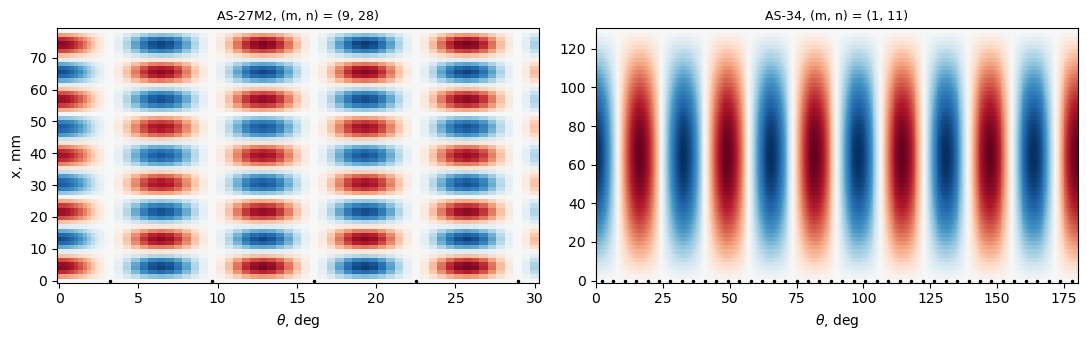

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, s, frac in ((axes[0], 'AS-27M2', 1/6), (axes[1], 'AS-34', 1.)):
    N, modes, N1, md_, skin = RES[(s, 'matched')][:5]
    plot_mode(ax, md_, modes[0][3], skin, shells[s]['R'],
              '%s, (m, n) = (%d, %d)' % (s, *modes[0][1:3]), shells[s]['ns'], frac)
axes[0].set_ylabel('x, mm')
plt.tight_layout()
plt.show()

## Case C of Poorveis and Kabir: external pressure (shell DUD-8 of [5])

Case C of [2] (Table 1, p. 119: 84 outside stringers, $L = 200$ mm, $R =
120.27$ mm, $h = 0.249$ mm, $A_1/(b_1 h) = 0.666$, $e_1/h = 4.030$, $I_1/(b
h^3) = 2.770$, $G_1 J_1/(bD) = 7.505$) is the shell DUD-8 of Abramovich,
Weller and Singer [5] (Table 1, p. 2: $h = 0.249$ mm, $L = 200$ mm, $R/h =
483$, $b_1/h = 36.15$, $A_1/(b_1 h) = 0.666$, $I_1/(b_1 h^3) = 2.77$, $e_1/h
= -4.03$, 84 integral external stringers, 7075-T6, $E = 7.5 \times 10^4$
MPa, $\nu = 0.3$; the footnote also prints $R = 120.12$ mm and $b_1 = 8.985$
mm, whereas $R/h$ and $b_1/h$ give 120.27 mm and 9.00 mm, the values of [2]
used here; $G_1 J_1/(bD)$ is from [2]). [2] defines $I_1$ about the
centroidal axis of the stringer and $e_1$ as its eccentricity, positive
outside (p. 118), [5] $e_1$ as the distance from the middle surface of the
skin to the centroid of the stringer and $I_{11}$ about its centroidal axis
(list of symbols, p. 1). The blade is, as for the shells of [1], the
rectangle $h_s = \sqrt{12 I_1/A_1}$, $t_s = A_1/h_s$ on the skin surface; its
centroid $(h + h_s)/2$ reproduces $e_1$ within 0.1 % (printed below). Nominal simple supports, found
between SS-3 and SS-4 by the vibration correlation technique (p. 3, p. 8).
Table 4 of [5] (p. 9), DUD-8, with the predictions of [5]:

| run | load | test $(n/m)$ | SS3 $(n/m)$ | SS4 $(n/m)$ | equivalent springs $(n/m)$ |
|---|---|---|---|---|---|
| 1 | external pressure, kPa | 13.55 (10/1) | 13.3 (11/1) | 16.7 (13/1) | 14.6 (11/1) |
| 2 | pressure, kPa, at $P = 4$ kN | 12.3 (9/1) | 12.0 (11/1) | 15.8 (13/1) | 14.2 (12/1) |
| 3 | pressure, kPa, at $P = 8$ kN | 11.10 (9/1) | 10.7 (11/1) | 14.8 (12/1) | 13.3 (12/1) |
| 4 | axial compression, kN | 32 (7/1) | 33.14 (9/1) | 54.05 (10/1) | 41.80 (10/1) |

Table 2 of [2] (p. 119) lists runs 1 and 3 as C1 and C2: test 0.001355 and
0.001110 kg/mm$^2$ (the latter at $P = 1.0587$ kg/mm), smeared (nonlinear)
0.001316 (10, 11) and 0.001095 (10, 11), discrete (nonlinear) 0.001480
(10, 11, 10) and 0.001270 (10, 10, 10), with $(M, n)$ or $(M, n, N)$, $M$
and $N$ the numbers of Ritz terms of [2].

**Units.** [2] converts with 1 kg = 10 N: 13.55 kPa = 0.001355 kg/mm$^2$,
$P = 8000/(2\pi \times 120.27)/10 = 1.0587$ kg/mm, $E = 7500$ kg/mm$^2$ = 75
GPa of [5]. The model uses these units (mm, $E = 7500$); $10^4 q$ is the
pressure in kPa, printed in the tables.

**Lateral or hydrostatic pressure.** [2] writes the external work of a radial
dead pressure $q_D$, adds that "for hydrostatic pressure, $P$ is related to
$q_D$ ($P = R q_D/2$)" and gives the load stiffness of a live pressure (p.
117), without saying which applies to case C. [5] says only "external
pressure"; its Fig. 1 (p. 3) draws the pressure on the shell wall and on the
bottom end plate inside the pressure vessel (closed ends, the end load of
hydrostatic pressure); whether the load-cell value $P$ includes this end load
is not said. Both are computed, first
as dead loads (a live variant follows the results): **lateral** ($\bar{N}_y = q
R$, $\bar{N}_x = 0$) and **hydrostatic** ($\bar{N}_x = q R/2$ in addition);
$P$ of runs 2 and 3 is added to $\bar{N}_x$.

**Smeared theory.** Equation (15) of [4] (p. 12) holds for any combination
of $\bar{N}_x$ and $\bar{N}_y$ (positive in compression, p. 8), "under
hydrostatic or lateral pressure" included: $(m\pi/L)^2 \bar{N}_x +
(n/R)^2 \bar{N}_y$ equals the right-hand side of `su.smeared_ss`; with
$\bar{N}_y = q R$ and $\bar{N}_x = P/(2\pi R) + \kappa q R/2$ ($\kappa = 0$
lateral, 1 hydrostatic) it gives $q$ (`su.smeared_ss_pressure`).

**Discrete model** (`su.buckling_pressure`): the assembly and SS3 ends of the
axial cases; the membrane pre-buckling state of equation (15): `Nyy` $= -q
R$ in the skin panels, no hoop force in the blades, and for the hydrostatic
end load the uniform axial strain of skin and blades of
`su.buckling_membrane`. The fixed load $P$ enters through the attributes
`Nxx_cte` of the panels, added to the constitutive stiffness, so that the
eigenvalue is the pressure. The membrane state is chosen, rather than a
linear static state from a pressure load, because it is the state of
equation (15): the comparison with the smeared theory is like for like, as
in the axial cases; a static state would add the bending of the skin at the
SS3 ends ($w = 0$ holds back the radial contraction), which [2] includes
with the nonlinear pre-buckling deformation.

In [7]:
# Poorveis and Kabir (2006), Table 1 (p. 119) = DUD-8, Table 1 of [5] (p. 2)
POORVEIS_C = (200.00, 120.27, 0.249, 84, 0.666, 4.030, 2.770, 7.505)
KPA = 1e4  # kPa per unit pressure of the model (1 kg = 10 N, mm)
# Table 4 of [5], p. 9 (kPa): P (kN), test, SS3, SS4, equivalent springs
DUD8 = {1: (0., 13.55, 13.3, 16.7, 14.6), 2: (4., 12.3, 12.0, 15.8, 14.2),
        3: (8., 11.10, 10.7, 14.8, 13.3)}
DUD8_AXIAL = (32., 33.14, 54.05, 41.80)  # kN, run 4
# Table 2 of [2], p. 119 (units of the model): test, smeared (nonlinear), discrete (nonlinear)
POORVEIS_CT2 = {1: (0.001355, 0.001316, 0.001480), 3: (0.001110, 0.001095, 0.001270)}
L, R, h, ns, Ab, e, Ib, eta = POORVEIS_C
b = 2*np.pi*R/ns
dc = shell(h, R, L, ns, Ab*b*h, Ib*b*h**3, e*h, eta*b*E*h**3/(12*(1 - NU**2))/G)
shells['C'] = dc
kN = 2*np.pi*R*10/1e3  # kN per unit axial force per unit circumference
LOADS = [(run, load, hyd, DUD8[run][0]/kN) for run in DUD8
         for load, hyd in (('lateral', False), ('hydrostatic', True))]
print('case C: b = %.3f mm, t_s = %.3f mm, h_s = %.3f mm, (h + h_s)/2 = %.4f mm (e_1 = %.4f mm), '
      'I_t1 = %.4f mm^4, I_t1/J_plate = %.3f; P = 8 kN: %.4f kg/mm'
      % (b, dc['ts'], dc['hs'], (h + dc['hs'])/2, dc['e'], dc['J'], dc['J']/dc['Jplate'], 8/kN))
Wsec = (dc['A'], dc['e'], dc['I'] + dc['A']*dc['e']**2)
Psec = plate_section(dc)
args = (dc['R'], dc['L'], dc['h'], E, NU, dc['b'])
smC = {}
rows = []
for run, load, hyd, P in LOADS:
    s = {'W': su.smeared_ss_pressure(*args, *Wsec, dc['J'], hyd, P),
         'matched': su.smeared_ss_pressure(*args, *Psec, dc['J'], hyd, P),
         'plate': su.smeared_ss_pressure(*args, *Psec, dc['Jplate'], hyd, P)}
    smC[(run, load)] = s
    P_kN, test, ss3 = DUD8[run][:3]
    qW = KPA*s['W'][0]
    rows.append([run, P_kN, load, '%.2f %s' % (qW, s['W'][1]),
                 '%.2f %s' % (KPA*s['matched'][0], s['matched'][1]), '%.2f' % (KPA*s['plate'][0]),
                 ss3, '%+.1f %%' % pct(qW, ss3), test, '%+.1f %%' % pct(qW, test)])
table(['run', 'P, kN', 'pressure', 'Eq. (15), section of [2], kPa (m, n)', 'Eq. (15), strip, matched J',
       'Eq. (15), strip, plate J', 'SS3 of [5]', 'section of [2] vs SS3 of [5]', 'test [5]',
       'section of [2] vs test'], rows)
sma = {'W': su.smeared_ss(*args, *Wsec, dc['J']), 'matched': su.smeared_ss(*args, *Psec, dc['J']),
       'plate': su.smeared_ss(*args, *Psec, dc['Jplate'])}
print('run 4, axial compression, Eq. (15): section of [2] %.2f kN %s (SS3 of [5] %.2f kN, %+.1f %%; test %.0f kN), '
      'strip matched J %.2f kN, plate J %.2f kN'
      % (kN*sma['W'][0], sma['W'][1], DUD8_AXIAL[1], pct(kN*sma['W'][0], DUD8_AXIAL[1]), DUD8_AXIAL[0],
         kN*sma['matched'][0], kN*sma['plate'][0]))

case C: b = 8.996 mm, t_s = 0.848 mm, h_s = 1.759 mm, (h + h_s)/2 = 1.0041 mm (e_1 = 1.0035 mm), I_t1 = 0.2482 mm^4, I_t1/J_plate = 0.694; P = 8 kN: 1.0587 kg/mm


| run | P, kN | pressure | Eq. (15), section of [2], kPa (m, n) | Eq. (15), strip, matched J | Eq. (15), strip, plate J | SS3 of [5] | section of [2] vs SS3 of [5] | test [5] | section of [2] vs test |
|---|---|---|---|---|---|---|---|---|---|
| 1 | 0.0 | lateral | 13.38 (1, 11) | 13.38 (1, 11) | 14.10 | 13.3 | +0.6 % | 13.55 | -1.3 % |
| 1 | 0.0 | hydrostatic | 13.18 (1, 11) | 13.19 (1, 11) | 13.90 | 13.3 | -0.9 % | 13.55 | -2.7 % |
| 2 | 4.0 | lateral | 12.08 (1, 11) | 12.08 (1, 11) | 12.80 | 12.0 | +0.7 % | 12.3 | -1.8 % |
| 2 | 4.0 | hydrostatic | 11.90 (1, 11) | 11.91 (1, 11) | 12.62 | 12.0 | -0.8 % | 12.3 | -3.2 % |
| 3 | 8.0 | lateral | 10.78 (1, 11) | 10.78 (1, 11) | 11.50 | 10.7 | +0.8 % | 11.1 | -2.9 % |
| 3 | 8.0 | hydrostatic | 10.62 (1, 11) | 10.63 (1, 11) | 11.34 | 10.7 | -0.7 % | 11.1 | -4.3 % |

run 4, axial compression, Eq. (15): section of [2] 34.04 kN (1, 9) (SS3 of [5] 33.14 kN, +2.7 %; test 32 kN), strip matched J 34.05 kN, plate J 35.53 kN


**Convergence** (matched $J$, the six pressure loadings).

In [8]:
LEVELS_C = [(12, 6, 4), (16, 8, 4), (20, 10, 5), (24, 10, 5)]
t0 = time.time()
RESC = {}
rows = []
for run, load, hyd, P in LOADS:
    prev = None
    for lev in LEVELS_C:
        RESC[(lev, 'matched', run, load)] = su.buckling_pressure(
            dc['R'], dc['h'], dc['L'], E, NU, dc['ts'], dc['Hs'], 'external', dc['ns'], *lev,
            D66_factor=dc['J']/dc['Jplate'], hydrostatic=hyd, Nx0=P)
        q, modes, md_, skin, ndof, dt = RESC[(lev, 'matched', run, load)]
        rows.append([run, load, lev, ndof, '%.1f' % dt, '%.3f' % (KPA*q), '(%d, %d)' % modes[0][1:3],
                     '' if prev is None else '%+.2f %%' % pct(q, prev)])
        prev = q
table(['run', 'pressure', 'm_x, n_y, n_b', 'dofs', 'time, s', 'q_cr, kPa', '(m, n)', 'change'], rows)
print('%.0f s' % (time.time() - t0))

| run | pressure | m_x, n_y, n_b | dofs | time, s | q_cr, kPa | (m, n) | change |
|---|---|---|---|---|---|---|---|
| 1 | lateral | (12, 6, 4) | 11495 | 4.7 | 13.397 | (1, 11) |  |
| 1 | lateral | (16, 8, 4) | 19151 | 9.3 | 13.385 | (1, 11) | -0.09 % |
| 1 | lateral | (20, 10, 5) | 31415 | 17.9 | 13.374 | (1, 11) | -0.08 % |
| 1 | lateral | (24, 10, 5) | 37631 | 28.0 | 13.366 | (1, 11) | -0.06 % |
| 1 | hydrostatic | (12, 6, 4) | 11495 | 4.7 | 13.199 | (1, 11) |  |
| 1 | hydrostatic | (16, 8, 4) | 19151 | 9.4 | 13.187 | (1, 11) | -0.09 % |
| 1 | hydrostatic | (20, 10, 5) | 31415 | 18.1 | 13.176 | (1, 11) | -0.08 % |
| 1 | hydrostatic | (24, 10, 5) | 37631 | 28.3 | 13.168 | (1, 11) | -0.06 % |
| 2 | lateral | (12, 6, 4) | 11495 | 4.5 | 12.076 | (1, 11) |  |
| 2 | lateral | (16, 8, 4) | 19151 | 9.2 | 12.063 | (1, 11) | -0.10 % |
| 2 | lateral | (20, 10, 5) | 31415 | 17.9 | 12.052 | (1, 11) | -0.09 % |
| 2 | lateral | (24, 10, 5) | 37631 | 27.6 | 12.044 | (1, 11) | -0.07 % |
| 2 | hydrostatic | (12, 6, 4) | 11495 | 4.9 | 11.897 | (1, 11) |  |
| 2 | hydrostatic | (16, 8, 4) | 19151 | 9.4 | 11.885 | (1, 11) | -0.10 % |
| 2 | hydrostatic | (20, 10, 5) | 31415 | 18.3 | 11.874 | (1, 11) | -0.09 % |
| 2 | hydrostatic | (24, 10, 5) | 37631 | 27.5 | 11.866 | (1, 11) | -0.07 % |
| 3 | lateral | (12, 6, 4) | 11495 | 4.6 | 10.754 | (1, 11) |  |
| 3 | lateral | (16, 8, 4) | 19151 | 9.1 | 10.742 | (1, 11) | -0.11 % |
| 3 | lateral | (20, 10, 5) | 31415 | 18.2 | 10.731 | (1, 11) | -0.10 % |
| 3 | lateral | (24, 10, 5) | 37631 | 26.4 | 10.723 | (1, 11) | -0.07 % |
| 3 | hydrostatic | (12, 6, 4) | 11495 | 4.7 | 10.595 | (1, 11) |  |
| 3 | hydrostatic | (16, 8, 4) | 19151 | 9.0 | 10.583 | (1, 11) | -0.11 % |
| 3 | hydrostatic | (20, 10, 5) | 31415 | 17.7 | 10.572 | (1, 11) | -0.10 % |
| 3 | hydrostatic | (24, 10, 5) | 37631 | 26.0 | 10.564 | (1, 11) | -0.07 % |

356 s


**Results** (finest level; plate $J$ as well; run 4 with
`su.buckling_membrane`). "Gap": discrete model against equation (15) for the
same strip and twisting stiffness. Pressures in kPa.

211 s


| run | P, kN | pressure | J | discrete q (m, n) | Eq. (15), same strip | gap | test [5] | vs test | SS3 of [5] | vs SS3 of [5] | smeared [2] | vs smeared [2] | discrete [2] | vs discrete [2] |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 0.0 | lateral | matched | 13.37 (1, 11) | 13.38 | **-0.1 %** | 13.55 | -1.4 % | 13.3 | +0.5 % | 13.16 | +1.6 % | 14.80 | -9.7 % |
| 1 | 0.0 | lateral | plate | 14.02 (1, 11) | 14.10 | **-0.6 %** | 13.55 | +3.5 % | 13.3 | +5.4 % | 13.16 | +6.5 % | 14.80 | -5.3 % |
| 1 | 0.0 | hydrostatic | matched | 13.17 (1, 11) | 13.19 | **-0.1 %** | 13.55 | -2.8 % | 13.3 | -1.0 % | 13.16 | +0.1 % | 14.80 | -11.0 % |
| 1 | 0.0 | hydrostatic | plate | 13.81 (1, 11) | 13.90 | **-0.6 %** | 13.55 | +1.9 % | 13.3 | +3.9 % | 13.16 | +5.0 % | 14.80 | -6.7 % |
| 2 | 4.0 | lateral | matched | 12.04 (1, 11) | 12.08 | **-0.3 %** | 12.3 | -2.1 % | 12.0 | +0.4 % | - | - | - | - |
| 2 | 4.0 | lateral | plate | 12.70 (1, 11) | 12.80 | **-0.8 %** | 12.3 | +3.2 % | 12.0 | +5.8 % | - | - | - | - |
| 2 | 4.0 | hydrostatic | matched | 11.87 (1, 11) | 11.91 | **-0.3 %** | 12.3 | -3.5 % | 12.0 | -1.1 % | - | - | - | - |
| 2 | 4.0 | hydrostatic | plate | 12.51 (1, 11) | 12.62 | **-0.8 %** | 12.3 | +1.7 % | 12.0 | +4.3 % | - | - | - | - |
| 3 | 8.0 | lateral | matched | 10.72 (1, 11) | 10.78 | **-0.6 %** | 11.1 | -3.4 % | 10.7 | +0.2 % | 10.95 | -2.1 % | 12.70 | -15.6 % |
| 3 | 8.0 | lateral | plate | 11.38 (1, 11) | 11.50 | **-1.1 %** | 11.1 | +2.5 % | 10.7 | +6.3 % | 10.95 | +3.9 % | 12.70 | -10.4 % |
| 3 | 8.0 | hydrostatic | matched | 10.56 (1, 11) | 10.63 | **-0.6 %** | 11.1 | -4.8 % | 10.7 | -1.3 % | 10.95 | -3.5 % | 12.70 | -16.8 % |
| 3 | 8.0 | hydrostatic | plate | 11.21 (1, 11) | 11.34 | **-1.1 %** | 11.1 | +1.0 % | 10.7 | +4.8 % | 10.95 | +2.4 % | 12.70 | -11.7 % |

| run 4, J | discrete P, kN (m, n) | Eq. (15), same strip | gap | test [5] | vs test | SS3 of [5] | vs SS3 of [5] |
|---|---|---|---|---|---|---|---|
| matched | 33.45 (1, 9) | 34.05 | **-1.8 %** | 32.0 | +4.5 % | 33.14 | +0.9 % |
| plate | 34.76 (1, 9) | 35.53 | **-2.2 %** | 32.0 | +8.6 % | 33.14 | +4.9 % |

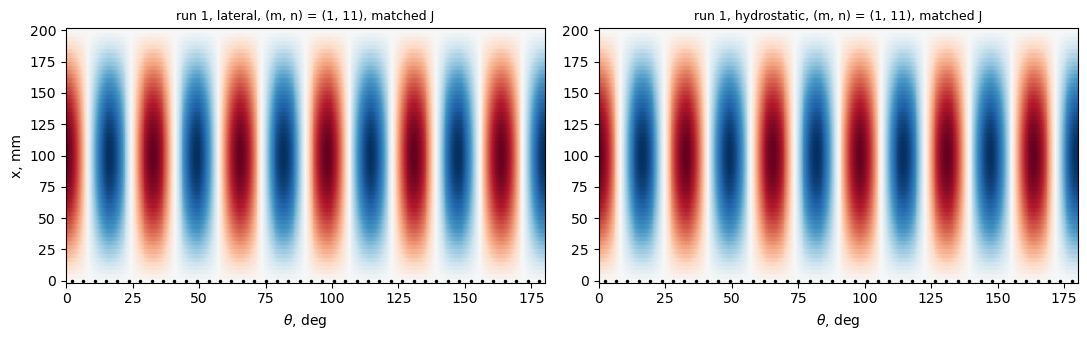

In [9]:
lev = LEVELS_C[-1]
t0 = time.time()
for run, load, hyd, P in LOADS:
    RESC[(lev, 'plate', run, load)] = su.buckling_pressure(
        dc['R'], dc['h'], dc['L'], E, NU, dc['ts'], dc['Hs'], 'external', dc['ns'], *lev,
        hydrostatic=hyd, Nx0=P)
axC = {J: su.buckling_membrane(dc['R'], dc['h'], dc['L'], E, NU, dc['ts'], dc['Hs'], 'external', 'SS',
                               dc['ns'], *lev, D66_factor=dc['J']/dc['Jplate'] if J == 'matched' else 1.)
       for J in ('matched', 'plate')}
print('%.0f s' % (time.time() - t0))
rows = []
for run, load, hyd, P in LOADS:
    P_kN, test, ss3, ss4, sp = DUD8[run]
    for J in ('matched', 'plate'):
        q, modes = RESC[(lev, J, run, load)][:2]
        sm = smC[(run, load)][J]
        row = [run, P_kN, load, J, '%.2f (%d, %d)' % (KPA*q, *modes[0][1:3]), '%.2f' % (KPA*sm[0]),
               '**%+.1f %%**' % pct(q, sm[0]), test, '%+.1f %%' % pct(KPA*q, test),
               ss3, '%+.1f %%' % pct(KPA*q, ss3)]
        if run in POORVEIS_CT2:
            t2, sm2, di2 = POORVEIS_CT2[run]
            row += ['%.2f' % (KPA*sm2), '%+.1f %%' % pct(q, sm2), '%.2f' % (KPA*di2), '%+.1f %%' % pct(q, di2)]
        else:
            row += ['-', '-', '-', '-']
        rows.append(row)
table(['run', 'P, kN', 'pressure', 'J', 'discrete q (m, n)', 'Eq. (15), same strip', 'gap', 'test [5]',
       'vs test', 'SS3 of [5]', 'vs SS3 of [5]', 'smeared [2]', 'vs smeared [2]', 'discrete [2]',
       'vs discrete [2]'], rows)
rows = []
for J in ('matched', 'plate'):
    N, modes = axC[J][:2]
    rows.append([J, '%.2f (%d, %d)' % (kN*N, *modes[0][1:3]), '%.2f' % (kN*sma[J][0]),
                 '**%+.1f %%**' % pct(N, sma[J][0]), DUD8_AXIAL[0], '%+.1f %%' % pct(kN*N, DUD8_AXIAL[0]),
                 DUD8_AXIAL[1], '%+.1f %%' % pct(kN*N, DUD8_AXIAL[1])])
table(['run 4, J', 'discrete P, kN (m, n)', 'Eq. (15), same strip', 'gap', 'test [5]', 'vs test',
       'SS3 of [5]', 'vs SS3 of [5]'], rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, load in zip(axes, ('lateral', 'hydrostatic')):
    q, modes, md_, skin = RESC[(lev, 'matched', 1, load)][:4]
    plot_mode(ax, md_, modes[0][3], skin, dc['R'],
              'run 1, %s, (m, n) = (%d, %d), matched J' % (load, *modes[0][1:3]), dc['ns'])
axes[0].set_ylabel('x, mm')
plt.tight_layout()
plt.show()

**Live (follower) pressure.** The pressure of the tests is the pressure of
a fluid, which stays normal to the deformed skin and acts on its deformed
area; [2] gives the load stiffness of this live pressure (p. 117) besides
the external work of the dead one. The live variant adds to the geometric
stiffness of the unit pressure the load stiffness of a unit follower pressure
on every skin panel, `Shell.calc_kCfollower` (first-order area vector, the
pressure on the middle surface of the skin, as the hoop force $q R$),
assembled at the offsets of the panels and reduced with the constraints of the
assembly (`su.follower_stiffness`). The end load of the hydrostatic pressure
acts on the rigid end plates and stays a dead axial load. The load
stiffness is unsymmetric in general, symmetric when every edge of the loaded
surface has $w = 0$ or a zero normal displacement (Hibbitt 1979; Schweizerhof
and Ramm 1984, Table 2): here the ends have $w = 0$, the symmetry planes $v
= 0$ and the skin panels are connected to each other, so its skew part is a
check (printed below). The eigenvalue problem is solved as an unsymmetric
one, `structsolve.lb(K, KG + KF, symmetric=False)`: the shift search of
`scipy.sparse.linalg.eigs` along the positive real axis for the lowest
positive real load multiplier, with a parity check of the number of real
multipliers below it. Finest level, matched $J$; run 1 also at the level
before (convergence).

In [10]:
t0 = time.time()
for run, load, hyd, P in LOADS:
    for lv in (LEVELS_C[-2:] if run == 1 else LEVELS_C[-1:]):
        RESC[(lv, 'live', run, load)] = su.buckling_pressure(
            dc['R'], dc['h'], dc['L'], E, NU, dc['ts'], dc['Hs'], 'external', dc['ns'], *lv,
            D66_factor=dc['J']/dc['Jplate'], hydrostatic=hyd, Nx0=P, follower=True)
print('%.0f s' % (time.time() - t0))
md_, skin = RESC[(lev, 'live', 1, 'lateral')][2:4]
KF = su.follower_stiffness(md_, skin)
print('skew part of the reduced load stiffness, ||KF - KF^T||/||KF|| = %.1e'
      % (np.sqrt(((KF - KF.T).data**2).sum())/np.sqrt((KF.data**2).sum())))
rows = []
for run, load, hyd, P in LOADS:
    P_kN, test, ss3 = DUD8[run][:3]
    qd = RESC[(lev, 'matched', run, load)][0]
    ql, modes = RESC[(lev, 'live', run, load)][:2]
    row = [run, P_kN, load, '%.2f' % (KPA*qd), '%.2f (%d, %d)' % (KPA*ql, *modes[0][1:3]),
           '**%+.2f %%**' % pct(ql, qd), test, '%+.1f %%' % pct(KPA*ql, test), ss3,
           '%+.1f %%' % pct(KPA*ql, ss3)]
    if run in POORVEIS_CT2:
        row += ['%.2f' % (KPA*POORVEIS_CT2[run][2]), '%+.1f %%' % pct(ql, POORVEIS_CT2[run][2])]
    else:
        row += ['-', '-']
    rows.append(row)
table(['run', 'P, kN', 'pressure', 'dead q', 'live q (m, n)', 'live vs dead', 'test [5]', 'live vs test',
       'SS3 of [5]', 'live vs SS3 of [5]', 'discrete [2]', 'live vs discrete [2]'], rows)
rows = []
for load in ('lateral', 'hydrostatic'):
    q1, q2 = (RESC[(lv, 'live', 1, load)][0] for lv in LEVELS_C[-2:])
    rows.append([load, LEVELS_C[-2], '%.3f' % (KPA*q1), LEVELS_C[-1], '%.3f' % (KPA*q2), '%+.2f %%' % pct(q2, q1)])
table(['run 1, live', 'level', 'q, kPa', 'level', 'q, kPa', 'change'], rows)

644 s


skew part of the reduced load stiffness, ||KF - KF^T||/||KF|| = 8.0e-11


| run | P, kN | pressure | dead q | live q (m, n) | live vs dead | test [5] | live vs test | SS3 of [5] | live vs SS3 of [5] | discrete [2] | live vs discrete [2] |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 0.0 | lateral | 13.37 | 13.26 (1, 11) | **-0.79 %** | 13.55 | -2.1 % | 13.3 | -0.3 % | 14.80 | -10.4 % |
| 1 | 0.0 | hydrostatic | 13.17 | 13.07 (1, 11) | **-0.78 %** | 13.55 | -3.6 % | 13.3 | -1.8 % | 14.80 | -11.7 % |
| 2 | 4.0 | lateral | 12.04 | 11.95 (1, 11) | **-0.79 %** | 12.3 | -2.9 % | 12.0 | -0.4 % | - | - |
| 2 | 4.0 | hydrostatic | 11.87 | 11.77 (1, 11) | **-0.78 %** | 12.3 | -4.3 % | 12.0 | -1.9 % | - | - |
| 3 | 8.0 | lateral | 10.72 | 10.64 (1, 11) | **-0.79 %** | 11.1 | -4.2 % | 10.7 | -0.6 % | 12.70 | -16.2 % |
| 3 | 8.0 | hydrostatic | 10.56 | 10.48 (1, 11) | **-0.78 %** | 11.1 | -5.6 % | 10.7 | -2.0 % | 12.70 | -17.5 % |

| run 1, live | level | q, kPa | level | q, kPa | change |
|---|---|---|---|---|---|
| lateral | (20, 10, 5) | 13.268 | (24, 10, 5) | 13.260 | -0.06 % |
| hydrostatic | (20, 10, 5) | 13.073 | (24, 10, 5) | 13.065 | -0.06 % |

**Interaction curve of DUD-8.** Shen, Zhou and Chen [3] (Fig. 3(a), p. 57)
give the interaction curve of DUD-8 under combined hydrostatic pressure and
axial load from their boundary-layer postbuckling theory (simply supported
ends, perfect shell and an imperfection $W^*/t = 0.04$), with the tests of
[5], as $R_x = \lambda_p/\lambda_p^*$ against $R_y = \lambda_q/\lambda_q^*$, the
loads divided by their theoretical values under axial compression alone
and external pressure alone (notation, p. 44), which [3] does not print.
Digitized here (reading precision $\pm 0.01$): perfect shell $R_x = 1.00,
0.92, 0.83, 0.74, 0.65, 0.55, 0.45, 0.34, 0.23, 0.12, 0$ at $R_y = 0, 0.1,
\ldots, 1.0$; tests $(R_y, R_x) = (0.00, 0.93), (0.83, 0.21), (0.93, 0.10),
(1.01, 0.00)$. The discrete model adds $P = 16$ and 24 kN (dead pressure)
to the runs of [5]; the curves of equation (15) are those of the section
of [2]. Left: absolute values with the tests and the SS3 predictions of [5]
(Table 4); right: each curve divided by its own values under pressure alone
and axial load alone, as [3] does.

111 s


| P, kN | pressure | discrete q, kPa (m, n) | Eq. (15), same strip | gap | R_x = P/P_ax | R_y = q/q(P = 0) |
|---|---|---|---|---|---|---|
| 0.0 | lateral | 13.37 (1, 11) | 13.38 | -0.1 % | 0.000 | 1.000 |
| 4.0 | lateral | 12.04 (1, 11) | 12.08 | -0.3 % | 0.120 | 0.901 |
| 8.0 | lateral | 10.72 (1, 11) | 10.78 | -0.6 % | 0.239 | 0.802 |
| 16.0 | lateral | 7.71 (1, 10) | 7.81 | -1.3 % | 0.478 | 0.577 |
| 24.0 | lateral | 4.50 (1, 10) | 4.67 | -3.6 % | 0.718 | 0.337 |
| 0.0 | hydrostatic | 13.17 (1, 11) | 13.19 | -0.1 % | 0.000 | 1.000 |
| 4.0 | hydrostatic | 11.87 (1, 11) | 11.91 | -0.3 % | 0.120 | 0.901 |
| 8.0 | hydrostatic | 10.56 (1, 11) | 10.63 | -0.6 % | 0.239 | 0.802 |
| 16.0 | hydrostatic | 7.57 (1, 10) | 7.67 | -1.3 % | 0.478 | 0.575 |
| 24.0 | hydrostatic | 4.42 (1, 10) | 4.59 | -3.6 % | 0.718 | 0.336 |

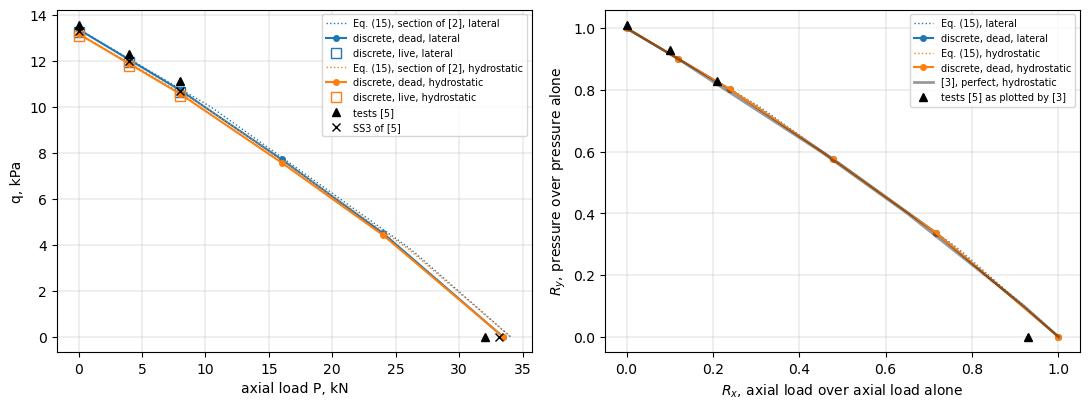

In [11]:
# Shen, Zhou and Chen (1993), Fig. 3(a), p. 57, digitized (+-0.01): perfect shell and tests of [5]
SHEN_F3A_RY = np.linspace(0., 1., 11)
SHEN_F3A_RX = np.array([1.00, 0.92, 0.83, 0.74, 0.65, 0.55, 0.45, 0.34, 0.23, 0.12, 0.])
SHEN_F3A_TESTS = np.array([(0.00, 0.93), (0.83, 0.21), (0.93, 0.10), (1.01, 0.00)])
P_EXTRA = (16., 24.)  # kN
t0 = time.time()
for P_kN in P_EXTRA:
    for load, hyd in (('lateral', False), ('hydrostatic', True)):
        RESC[(lev, 'matched', 'P%g' % P_kN, load)] = su.buckling_pressure(
            dc['R'], dc['h'], dc['L'], E, NU, dc['ts'], dc['Hs'], 'external', dc['ns'], *lev,
            D66_factor=dc['J']/dc['Jplate'], hydrostatic=hyd, Nx0=P_kN/kN)
print('%.0f s' % (time.time() - t0))
Pax = kN*axC['matched'][0]  # discrete, axial compression alone, kN
rows = []
curves = {}
for load, hyd in (('lateral', False), ('hydrostatic', True)):
    keys = sorted([(run, DUD8[run][0]) for run in DUD8] + [('P%g' % P_kN, P_kN) for P_kN in P_EXTRA],
                  key=lambda k: k[1])
    q0 = RESC[(lev, 'matched', 1, load)][0]
    pts = []
    for key, P_kN in keys:
        q, modes = RESC[(lev, 'matched', key, load)][:2]
        pts.append((P_kN, KPA*q))
        sm = su.smeared_ss_pressure(*args, *Psec, dc['J'], hyd, P_kN/kN)
        rows.append([P_kN, load, '%.2f (%d, %d)' % (KPA*q, *modes[0][1:3]), '%.2f' % (KPA*sm[0]),
                     '%+.1f %%' % pct(q, sm[0]), '%.3f' % (P_kN/Pax), '%.3f' % (q/q0)])
    curves[load] = np.array(pts + [(Pax, 0.)])
table(['P, kN', 'pressure', 'discrete q, kPa (m, n)', 'Eq. (15), same strip', 'gap', 'R_x = P/P_ax',
       'R_y = q/q(P = 0)'], rows)

Ps = np.linspace(0., kN*sma['W'][0], 60)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for load, hyd, c in (('lateral', False, 'C0'), ('hydrostatic', True, 'C1')):
    qs = np.array([su.smeared_ss_pressure(*args, *Wsec, dc['J'], hyd, P/kN)[0] for P in Ps])
    axes[0].plot(Ps, KPA*qs, c + ':', lw=1, label='Eq. (15), section of [2], %s' % load)
    axes[0].plot(curves[load][:, 0], curves[load][:, 1], c + 'o-', ms=4, label='discrete, dead, %s' % load)
    axes[0].plot([DUD8[r][0] for r in DUD8], [KPA*RESC[(lev, 'live', r, load)][0] for r in DUD8], c + 's',
                 mfc='none', ms=7, label='discrete, live, %s' % load)
    ok = qs > 0
    axes[1].plot(Ps[ok]/Ps[-1], qs[ok]/qs[0], c + ':', lw=1, label='Eq. (15), %s' % load)
    axes[1].plot(curves[load][:, 0]/Pax, curves[load][:, 1]/curves[load][0, 1], c + 'o-', ms=4,
                 label='discrete, dead, %s' % load)
axes[0].plot([DUD8[r][0] for r in DUD8] + [DUD8_AXIAL[0]], [DUD8[r][1] for r in DUD8] + [0.], 'k^',
             label='tests [5]')
axes[0].plot([DUD8[r][0] for r in DUD8] + [DUD8_AXIAL[1]], [DUD8[r][2] for r in DUD8] + [0.], 'kx',
             label='SS3 of [5]')
axes[0].set_xlabel('axial load P, kN')
axes[0].set_ylabel('q, kPa')
axes[1].plot(SHEN_F3A_RX, SHEN_F3A_RY, 'k-', lw=2, alpha=0.4, label='[3], perfect, hydrostatic')
axes[1].plot(SHEN_F3A_TESTS[:, 1], SHEN_F3A_TESTS[:, 0], 'k^', label='tests [5] as plotted by [3]')
axes[1].set_xlabel('$R_x$, axial load over axial load alone')
axes[1].set_ylabel('$R_y$, pressure over pressure alone')
for ax in axes:
    ax.grid(True, lw=0.3)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

## Shell DUD-10 of [5]: combined loading in the reversed sequence

DUD-10 is the "twin" of DUD-8 (case C), machined from the same blank ([5],
p. 2). [5] buckled it four times (Table 5, p. 10), the first combined run in
the reversed sequence: the pressure held at $p = 11.1$ kPa and the axial load
increased up to buckling (run 2), then the axial load held at $P = 3.8$ kN
and the pressure increased (run 3). Shen, Zhou and Chen [3] plot its
interaction curve as Fig. 3(b) (p. 57). Neither [2] nor [3] gives its section;
the values below are those of [5].

**Geometry and stringers.** Table 1 of [5] (p. 2), DUD-10: $h = 0.252$ mm,
$L = 200$ mm, $R/h = 476$, $L/R = 1.665$, stringer height $d_1 = 1.755$ mm
and width $c_1 = 0.85$ mm, $b_1/h = 35.65$, $A_{11}/(b_1 h) = 0.659$,
$I_{11}/(b_1 h^3) = 2.66$, $e_1/h = -3.98$ ($d_1$ the height of the
stringer, $e_1$ the distance from the middle surface of the skin to the
centroid of the stringer, $I_{11}$ about its centroidal axis; list of
symbols, p. 1); footnote: $R = 120.12$ mm,
$b_1 = 8.985$ mm for DUD-8 to DUD-11, 84 integral external stringers,
7075-T6, $E = 7.5 \times 10^4$ MPa, $\nu = 0.3$. For DUD-10 these agree:
$L/(L/R) = 120.12$ mm, $84 \times 35.65 h/(2\pi) = 120.11$ mm, while
$476 h = 119.95$ mm is $R/h$ rounded to an integer; $R = 120.12$ mm is used,
119.95 mm as a sensitivity of equation (15). The stringer is the rectangle
$c_1 \times d_1$ on the skin surface: $c_1 d_1$, $c_1 d_1^3/12$ and $(h + d_1)/2$ reproduce the
area, the moment of inertia and the eccentricity of Table 1 (checked below);
the model takes $h_s = \sqrt{12 I_{11}/A_{11}}$ and $t_s = A_{11}/h_s$ from
the non-dimensional values, a blade on the skin surface as for the other
shells. The torsion constant is
not printed for DUD-10; it is taken as the Saint-Venant constant of the
rectangle $c_1 \times d_1$ (the $I_{t1}$ of the shells of [1] is that of the
rectangle, and for DUD-8 the rectangle is within 1 % of $G_1 J_1/(bD)$ of
[2]; printed below), with the plate $J$ and, in equation (15), $J = 0$ as
the sensitivity.

**Tests and predictions of [5]** (Table 5, p. 10; ends between SS-3 and SS-4
by the vibration correlation technique, p. 9; modes $(n/m)$):

| run | load | test | SS3 | SS4 | equivalent springs |
|---|---|---|---|---|---|
| 1 | external pressure, kPa | 12.6 (10/1) | 13.6 (11/1) | 17.1 (13/1) | 14.5 (11/1) |
| 2 | axial load, kN, at $p = 11.1$ kPa | 3.80 (9/1) | 7.99 (11/1) | 23.42 (12/1) | 13.80 (11/1) |
| 3 | pressure, kPa, at $P = 3.8$ kN | 11.3 (9/1) | 12.4 (11/1) | 16.3 (12/1) | 13.2 (11/1) |
| 4 | axial compression, kN | 32. (7/1) | 33.66 (9/1) | 54.90 (12/1) | 41.20 (10/1) |

The ratios $\varrho_{SS3} = 0.93$, 0.48, 0.91, 0.95 are test over SS3. [5]
attributes the low axial load of run 2 to the growth of the initial
imperfections under the pressure held first (p. 8): the pressure of run 3
(11.3 kPa at 3.8 kN) is close to the 11.1 kPa at which run 2 buckled at 3.8
kN.

**Model.** Units, pressure types (lateral and hydrostatic, dead and live),
equation (15) and the discrete model are those of case C. Runs 1 and 3 give
the pressure at a fixed axial load. Run 2 holds the pressure: equation (15)
and the discrete model give the axial load at which the critical pressure
equals 11.1 kPa, found as the root of $q(P) - 11.1$ kPa ($q$ decreases
monotonically with $P$): Brent's method on equation (15), the secant method
on the discrete model (bisection when a step leaves the bracket of the root), to a relative tolerance of $10^{-4}$ on $q$.

In [12]:
from scipy.optimize import brentq


def rect_J(a, c):
    # Saint-Venant torsion constant of a rectangle a x c
    a, c = max(a, c), min(a, c)
    return c**3*a*(1/3 - 64/np.pi**5*c/a*np.tanh(np.pi*a/(2*c)))


# Abramovich, Weller and Singer (1988) [5], Table 1 (p. 2), DUD-10: h, L (mm), R/h, L/R, d1, c1 (mm),
# b1/h, A11/(b1 h), I11/(b1 h^3), e1/h; footnote: R = 120.12 mm, 84 external stringers
hE, LE, RhE, LRE, d1, c1, b1hE, AbE, IbE, ehE = (0.252, 200., 476, 1.665, 1.755, 0.85, 35.65, 0.659, 2.66, -3.98)
RE, nsE = 120.12, 84
# Table 5 of [5] (p. 10): test, SS3, SS4, equivalent springs; runs 1 and 3 in kPa, runs 2 and 4 in kN
DUD10 = {1: (12.6, 13.6, 17.1, 14.5), 2: (3.80, 7.99, 23.42, 13.80), 3: (11.3, 12.4, 16.3, 13.2),
         4: (32., 33.66, 54.90, 41.20)}
P_RUN3, Q_RUN2 = 3.8, 11.1  # kN, kPa: the load held constant in runs 3 and 2
bE = 2*np.pi*RE/nsE
de = shell(hE, RE, LE, nsE, AbE*bE*hE, IbE*bE*hE**3, -ehE*hE, rect_J(c1, d1))
shells['DUD-10'] = de
kNe = 2*np.pi*RE*10/1e3  # kN per unit axial force per unit circumference
DE = E*hE**3/(12*(1 - NU**2))
print('R: L/(L/R) = %.2f mm, 84 b1/(2 pi) = %.2f mm, (R/h) h = %.2f mm; b1 = 2 pi R/84 = %.3f mm (b1/h h = %.3f mm)'
      % (LE/LRE, nsE*b1hE*hE/(2*np.pi), RhE*hE, bE, b1hE*hE))
print('rectangle c1 x d1 against Table 1: area %.4f (%.4f) mm^2, I11 %.4f (%.4f) mm^4, e1 %.4f (%.4f) mm'
      % (c1*d1, de['A'], c1*d1**3/12, de['I'], (hE + d1)/2, de['e']))
print('model: h_s = %.3f mm (d1 = %.3f), t_s = %.3f mm (c1 = %.2f), J = %.4f mm^4, G J/(b D) = %.3f, '
      'J/J_plate = %.3f, theta = %.3f'
      % (de['hs'], d1, de['ts'], c1, de['J'], G*de['J']/(bE*DE), de['J']/de['Jplate'],
         k4*bE/(2*np.pi*np.sqrt(RE*hE))))
print('DUD-8 (case C): J of the rectangle t_s x h_s %.4f mm^4 against I_t1 = %.4f mm^4 of [2] (%+.1f %%)'
      % (rect_J(dc['ts'], dc['hs']), dc['J'], pct(rect_J(dc['ts'], dc['hs']), dc['J'])))

argsE = (de['R'], de['L'], de['h'], E, NU, de['b'])
WsecE = (de['A'], de['e'], de['I'] + de['A']*de['e']**2)
PsecE = plate_section(de)
SECS_E = {'W': (argsE, WsecE, de['J']), 'W_J0': (argsE, WsecE, 0.),
          'W_R': ((RhE*hE,) + argsE[1:-1] + (2*np.pi*RhE*hE/nsE,), WsecE, de['J']),
          'matched': (argsE, PsecE, de['J']), 'plate': (argsE, PsecE, de['Jplate'])}


def smeared_E(key, run, hyd):
    # equation (15) for run 1 to 4: pressure (kPa) of runs 1 and 3, axial load (kN) of runs 2 and 4, (m, n)
    a, sec, J = SECS_E[key]
    kN_ = 2*np.pi*a[0]*10/1e3
    if run == 4:
        N, mn = su.smeared_ss(*a, *sec, J)
        return kN_*N, mn
    if run in (1, 3):
        q, mn = su.smeared_ss_pressure(*a, *sec, J, hyd, (P_RUN3 if run == 3 else 0.)/kN_)
        return KPA*q, mn
    f = lambda N: su.smeared_ss_pressure(*a, *sec, J, hyd, N)[0] - Q_RUN2/KPA
    N = brentq(f, 0., su.smeared_ss(*a, *sec, J)[0], xtol=1e-12)
    return kN_*N, su.smeared_ss_pressure(*a, *sec, J, hyd, N)[1]


smE = {}
rows = []
for run in (1, 2, 3, 4):
    for load, hyd in ((('lateral', False), ('hydrostatic', True)) if run < 4 else (('axial', False),)):
        smE[(run, load)] = {k: smeared_E(k, run, hyd) for k in SECS_E}
        s = smE[(run, load)]
        test, ss3 = DUD10[run][:2]
        rows.append([run, load, '%.2f %s' % s['W'], '%.2f' % s['W_J0'][0], '%.2f' % s['W_R'][0],
                     '%.2f %s' % s['matched'], '%.2f' % s['plate'][0], ss3, '%+.1f %%' % pct(s['W'][0], ss3),
                     test, '%+.1f %%' % pct(s['W'][0], test)])
table(['run', 'load', 'Eq. (15), section of [5] (m, n)', 'same, J = 0', 'same, R = 119.95 mm',
       'Eq. (15), strip, matched J', 'Eq. (15), strip, plate J', 'SS3 of [5]', 'section of [5] vs SS3 of [5]',
       'test [5]', 'section of [5] vs test'], rows)
print('runs 1 and 3: pressure, kPa; runs 2 and 4: axial load, kN')

R: L/(L/R) = 120.12 mm, 84 b1/(2 pi) = 120.10 mm, (R/h) h = 119.95 mm; b1 = 2 pi R/84 = 8.985 mm (b1/h h = 8.984 mm)
rectangle c1 x d1 against Table 1: area 1.4917 (1.4921) mm^2, I11 0.3829 (0.3825) mm^4, e1 1.0035 (1.0030) mm
model: h_s = 1.754 mm (d1 = 1.755), t_s = 0.851 mm (c1 = 0.85), J = 0.2504 mm^4, G J/(b D) = 7.315, J/J_plate = 0.696, theta = 0.472
DUD-8 (case C): J of the rectangle t_s x h_s 0.2498 mm^4 against I_t1 = 0.2482 mm^4 of [2] (+0.7 %)


| run | load | Eq. (15), section of [5] (m, n) | same, J = 0 | same, R = 119.95 mm | Eq. (15), strip, matched J | Eq. (15), strip, plate J | SS3 of [5] | section of [5] vs SS3 of [5] | test [5] | section of [5] vs test |
|---|---|---|---|---|---|---|---|---|---|---|
| 1 | lateral | 13.72 (1, 11) | 12.07 | 13.75 | 13.72 (1, 11) | 14.44 | 13.6 | +0.9 % | 12.6 | +8.9 % |
| 1 | hydrostatic | 13.52 (1, 11) | 11.89 | 13.55 | 13.52 (1, 11) | 14.23 | 13.6 | -0.6 % | 12.6 | +7.3 % |
| 2 | lateral | 8.07 (1, 11) | 2.98 | 8.16 | 8.07 (1, 11) | 10.20 | 7.99 | +0.9 % | 3.8 | +112.3 % |
| 2 | hydrostatic | 7.56 (1, 11) | 2.47 | 7.66 | 7.56 (1, 11) | 9.70 | 7.99 | -5.4 % | 3.8 | +99.0 % |
| 3 | lateral | 12.48 (1, 11) | 10.83 | 12.51 | 12.48 (1, 11) | 13.21 | 12.4 | +0.7 % | 11.3 | +10.5 % |
| 3 | hydrostatic | 12.30 (1, 11) | 10.68 | 12.33 | 12.30 (1, 11) | 13.02 | 12.4 | -0.8 % | 11.3 | +8.9 % |
| 4 | axial | 34.58 (1, 9) | 31.17 | 34.59 | 34.58 (1, 9) | 36.07 | 33.66 | +2.7 % | 32.0 | +8.1 % |

runs 1 and 3: pressure, kPa; runs 2 and 4: axial load, kN


**Convergence** (matched $J$, runs 1 and 3, dead pressure; the levels of
case C).

In [13]:
t0 = time.time()
RESE = {}
LOADS_E = [(run, load, hyd, P_RUN3/kNe if run == 3 else 0.) for run in (1, 3)
           for load, hyd in (('lateral', False), ('hydrostatic', True))]


def runE(lev, J, P, hyd, follower=False):
    return su.buckling_pressure(de['R'], de['h'], de['L'], E, NU, de['ts'], de['Hs'], 'external', de['ns'], *lev,
                                D66_factor=de['J']/de['Jplate'] if J == 'matched' else 1., hydrostatic=hyd,
                                Nx0=P, follower=follower)


rows = []
for run, load, hyd, P in LOADS_E:
    prev = None
    for lv in LEVELS_C:
        RESE[(lv, 'matched', run, load)] = runE(lv, 'matched', P, hyd)
        q, modes, md_, skin, ndof, dt = RESE[(lv, 'matched', run, load)]
        rows.append([run, load, lv, ndof, '%.1f' % dt, '%.3f' % (KPA*q), '(%d, %d)' % modes[0][1:3],
                     '' if prev is None else '%+.2f %%' % pct(q, prev)])
        prev = q
table(['run', 'pressure', 'm_x, n_y, n_b', 'dofs', 'time, s', 'q_cr, kPa', '(m, n)', 'change'], rows)
print('%.0f s' % (time.time() - t0))

| run | pressure | m_x, n_y, n_b | dofs | time, s | q_cr, kPa | (m, n) | change |
|---|---|---|---|---|---|---|---|
| 1 | lateral | (12, 6, 4) | 11495 | 4.6 | 13.736 | (1, 11) |  |
| 1 | lateral | (16, 8, 4) | 19151 | 9.3 | 13.723 | (1, 11) | -0.09 % |
| 1 | lateral | (20, 10, 5) | 31415 | 19.1 | 13.712 | (1, 11) | -0.08 % |
| 1 | lateral | (24, 10, 5) | 37631 | 28.4 | 13.704 | (1, 11) | -0.06 % |
| 1 | hydrostatic | (12, 6, 4) | 11495 | 4.5 | 13.533 | (1, 11) |  |
| 1 | hydrostatic | (16, 8, 4) | 19151 | 9.5 | 13.521 | (1, 11) | -0.09 % |
| 1 | hydrostatic | (20, 10, 5) | 31415 | 19.0 | 13.510 | (1, 11) | -0.08 % |
| 1 | hydrostatic | (24, 10, 5) | 37631 | 28.9 | 13.502 | (1, 11) | -0.06 % |
| 3 | lateral | (12, 6, 4) | 11495 | 4.6 | 12.480 | (1, 11) |  |
| 3 | lateral | (16, 8, 4) | 19151 | 10.0 | 12.468 | (1, 11) | -0.10 % |
| 3 | lateral | (20, 10, 5) | 31415 | 19.2 | 12.457 | (1, 11) | -0.09 % |
| 3 | lateral | (24, 10, 5) | 37631 | 29.4 | 12.449 | (1, 11) | -0.06 % |
| 3 | hydrostatic | (12, 6, 4) | 11495 | 4.6 | 12.296 | (1, 11) |  |
| 3 | hydrostatic | (16, 8, 4) | 19151 | 9.8 | 12.284 | (1, 11) | -0.10 % |
| 3 | hydrostatic | (20, 10, 5) | 31415 | 19.4 | 12.273 | (1, 11) | -0.09 % |
| 3 | hydrostatic | (24, 10, 5) | 37631 | 29.5 | 12.265 | (1, 11) | -0.06 % |

250 s


**Results** (finest level; dead pressure; plate $J$ for runs 1, 3 and 4).
Run 2: the axial load at which the critical pressure is 11.1 kPa (secant
iterations from the results at $P = 3.8$ and 8 kN; the number of iterations
is printed); run 4 with `su.buckling_membrane`. The loads at $P = 8$, 16 and
24 kN complete the interaction curve. "Gap": discrete model against equation
(15) for the same strip and twisting stiffness.

In [14]:
t0 = time.time()
for run, load, hyd, P in LOADS_E:
    RESE[(lev, 'plate', run, load)] = runE(lev, 'plate', P, hyd)
for P_kN in (8., 16., 24.):
    for load, hyd in (('lateral', False), ('hydrostatic', True)):
        RESE[(lev, 'matched', 'P%g' % P_kN, load)] = runE(lev, 'matched', P_kN/kNe, hyd)
axE = {J: su.buckling_membrane(de['R'], de['h'], de['L'], E, NU, de['ts'], de['Hs'], 'external', 'SS',
                               de['ns'], *lev, D66_factor=de['J']/de['Jplate'] if J == 'matched' else 1.)
       for J in ('matched', 'plate')}


def secant_P(q_target, P0, q0, P1, q1, run_at, Pmax, tol=1e-4, maxit=20):
    # axial force (units of the model) at which the critical pressure equals q_target: secant steps
    # kept inside the bracket [lo, hi], q(lo) > q_target > q(hi), bisection when a step leaves it;
    # Pmax, the axial load alone (q = 0), is the first upper bound
    lo, hi = 0., Pmax
    for P, q in ((P0, q0), (P1, q1)):
        lo, hi = (max(lo, P), hi) if q > q_target else (lo, min(hi, P))
    for it in range(1, maxit + 1):
        P = P1 + (q_target - q1)*(P1 - P0)/(q1 - q0)
        if not lo < P < hi:
            P = (lo + hi)/2
        res = run_at(P)
        if abs(res[0]/q_target - 1) < tol:
            return P, res, it
        lo, hi = (max(lo, P), hi) if res[0] > q_target else (lo, min(hi, P))
        P0, q0, P1, q1 = P1, q1, P, res[0]
    raise RuntimeError('secant: no convergence')


for load, hyd in (('lateral', False), ('hydrostatic', True)):
    RESE[(lev, 'matched', 2, load)] = secant_P(
        Q_RUN2/KPA, P_RUN3/kNe, RESE[(lev, 'matched', 3, load)][0], 8./kNe,
        RESE[(lev, 'matched', 'P8', load)][0], lambda P: runE(lev, 'matched', P, hyd), axE['matched'][0])
print('%.0f s' % (time.time() - t0))
rows = []
for run in (1, 2, 3, 4):
    test, ss3, ss4, sp = DUD10[run]
    for load in (('lateral', 'hydrostatic') if run < 4 else ('axial',)):
        for J in (('matched', 'plate') if run != 2 else ('matched',)):
            sm = smE[(run, load)][J]
            if run in (1, 3):
                q, modes = RESE[(lev, J, run, load)][:2]
                val, extra = KPA*q, ''
            elif run == 2:
                P, res, it = RESE[(lev, J, 2, load)]
                modes = res[1]
                val, extra = kNe*P, ', %d secant iterations, q = %.4f kPa' % (it, KPA*res[0])
            else:
                N, modes = axE[J][:2]
                val, extra = kNe*N, ''
            rows.append([run, load, J, '%.2f (%d, %d)%s' % (val, *modes[0][1:3], extra), '%.2f' % sm[0],
                         '**%+.1f %%**' % pct(val, sm[0]), test, '%+.1f %%' % pct(val, test), ss3,
                         '%+.1f %%' % pct(val, ss3), ss4, sp])
table(['run', 'load', 'J', 'discrete (m, n)', 'Eq. (15), same strip', 'gap', 'test [5]', 'vs test',
       'SS3 of [5]', 'vs SS3 of [5]', 'SS4 of [5]', 'springs of [5]'], rows)
print('runs 1 and 3: pressure, kPa; runs 2 and 4: axial load, kN')

406 s


| run | load | J | discrete (m, n) | Eq. (15), same strip | gap | test [5] | vs test | SS3 of [5] | vs SS3 of [5] | SS4 of [5] | springs of [5] |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 | lateral | matched | 13.70 (1, 11) | 13.72 | **-0.1 %** | 12.6 | +8.8 % | 13.6 | +0.8 % | 17.1 | 14.5 |
| 1 | lateral | plate | 14.36 (1, 11) | 14.44 | **-0.5 %** | 12.6 | +14.0 % | 13.6 | +5.6 % | 17.1 | 14.5 |
| 1 | hydrostatic | matched | 13.50 (1, 11) | 13.52 | **-0.1 %** | 12.6 | +7.2 % | 13.6 | -0.7 % | 17.1 | 14.5 |
| 1 | hydrostatic | plate | 14.15 (1, 11) | 14.23 | **-0.6 %** | 12.6 | +12.3 % | 13.6 | +4.0 % | 17.1 | 14.5 |
| 2 | lateral | matched | 7.88 (1, 11), 1 secant iterations, q = 11.1000 kPa | 8.07 | **-2.3 %** | 3.8 | +107.4 % | 7.99 | -1.4 % | 23.42 | 13.8 |
| 2 | hydrostatic | matched | 7.38 (1, 11), 1 secant iterations, q = 11.1000 kPa | 7.56 | **-2.4 %** | 3.8 | +94.2 % | 7.99 | -7.7 % | 23.42 | 13.8 |
| 3 | lateral | matched | 12.45 (1, 11) | 12.48 | **-0.3 %** | 11.3 | +10.2 % | 12.4 | +0.4 % | 16.3 | 13.2 |
| 3 | lateral | plate | 13.11 (1, 11) | 13.21 | **-0.8 %** | 11.3 | +16.0 % | 12.4 | +5.7 % | 16.3 | 13.2 |
| 3 | hydrostatic | matched | 12.26 (1, 11) | 12.30 | **-0.3 %** | 11.3 | +8.5 % | 12.4 | -1.1 % | 16.3 | 13.2 |
| 3 | hydrostatic | plate | 12.91 (1, 11) | 13.02 | **-0.8 %** | 11.3 | +14.3 % | 12.4 | +4.1 % | 16.3 | 13.2 |
| 4 | axial | matched | 33.97 (1, 9) | 34.58 | **-1.8 %** | 32.0 | +6.1 % | 33.66 | +0.9 % | 54.9 | 41.2 |
| 4 | axial | plate | 35.28 (1, 9) | 36.07 | **-2.2 %** | 32.0 | +10.3 % | 33.66 | +4.8 % | 54.9 | 41.2 |

runs 1 and 3: pressure, kPa; runs 2 and 4: axial load, kN


**Live (follower) pressure**, as for case C: runs 1 and 3, and run 2 (the
secant iterations repeated with the live pressure, from the live results at
$P = 0$ and 3.8 kN); finest level, matched $J$, run 1 also at the level
before (convergence).

In [15]:
t0 = time.time()
for run, load, hyd, P in LOADS_E:
    for lv in (LEVELS_C[-2:] if run == 1 else LEVELS_C[-1:]):
        RESE[(lv, 'live', run, load)] = runE(lv, 'matched', P, hyd, follower=True)
for load, hyd in (('lateral', False), ('hydrostatic', True)):
    RESE[(lev, 'live', 2, load)] = secant_P(
        Q_RUN2/KPA, 0., RESE[(lev, 'live', 1, load)][0], P_RUN3/kNe, RESE[(lev, 'live', 3, load)][0],
        lambda P: runE(lev, 'matched', P, hyd, follower=True), axE['matched'][0])
print('%.0f s' % (time.time() - t0))
rows = []
for run in (1, 2, 3):
    test, ss3 = DUD10[run][:2]
    for load in ('lateral', 'hydrostatic'):
        if run == 2:
            Pd, Pl = RESE[(lev, 'matched', 2, load)][0], RESE[(lev, 'live', 2, load)][0]
            modes = RESE[(lev, 'live', 2, load)][1][1]
            vd, vl = kNe*Pd, kNe*Pl
        else:
            vd = KPA*RESE[(lev, 'matched', run, load)][0]
            vl, modes = RESE[(lev, 'live', run, load)][:2]
            vl *= KPA
        rows.append([run, load, '%.2f' % vd, '%.2f (%d, %d)' % (vl, *modes[0][1:3]), '**%+.2f %%**' % pct(vl, vd),
                     test, '%+.1f %%' % pct(vl, test), ss3, '%+.1f %%' % pct(vl, ss3)])
table(['run', 'pressure', 'dead', 'live (m, n)', 'live vs dead', 'test [5]', 'live vs test', 'SS3 of [5]',
       'live vs SS3 of [5]'], rows)
rows = []
for load in ('lateral', 'hydrostatic'):
    q1, q2 = (RESE[(lv, 'live', 1, load)][0] for lv in LEVELS_C[-2:])
    rows.append([load, LEVELS_C[-2], '%.3f' % (KPA*q1), LEVELS_C[-1], '%.3f' % (KPA*q2), '%+.2f %%' % pct(q2, q1)])
table(['run 1, live', 'level', 'q, kPa', 'level', 'q, kPa', 'change'], rows)
print('runs 1 and 3: pressure, kPa; run 2: axial load, kN')

628 s


| run | pressure | dead | live (m, n) | live vs dead | test [5] | live vs test | SS3 of [5] | live vs SS3 of [5] |
|---|---|---|---|---|---|---|---|---|
| 1 | lateral | 13.70 | 13.60 (1, 11) | **-0.79 %** | 12.6 | +7.9 % | 13.6 | -0.0 % |
| 1 | hydrostatic | 13.50 | 13.40 (1, 11) | **-0.78 %** | 12.6 | +6.3 % | 13.6 | -1.5 % |
| 2 | lateral | 7.88 | 7.61 (1, 11) | **-3.41 %** | 3.8 | +100.3 % | 7.99 | -4.7 % |
| 2 | hydrostatic | 7.38 | 7.11 (1, 11) | **-3.65 %** | 3.8 | +87.1 % | 7.99 | -11.0 % |
| 3 | lateral | 12.45 | 12.35 (1, 11) | **-0.79 %** | 11.3 | +9.3 % | 12.4 | -0.4 % |
| 3 | hydrostatic | 12.26 | 12.17 (1, 11) | **-0.78 %** | 11.3 | +7.7 % | 12.4 | -1.9 % |

| run 1, live | level | q, kPa | level | q, kPa | change |
|---|---|---|---|---|---|
| lateral | (20, 10, 5) | 13.603 | (24, 10, 5) | 13.595 | -0.06 % |
| hydrostatic | (20, 10, 5) | 13.404 | (24, 10, 5) | 13.396 | -0.06 % |

runs 1 and 3: pressure, kPa; run 2: axial load, kN


**Interaction curve of DUD-10.** Fig. 3(b) of [3] (p. 57; $R/t = 477$, $Z =
1261$): the perfect shell and $W^*/t = 0.05$ under combined hydrostatic
pressure and axial load, with the tests of [5], normalized as in Fig. 3(a).
Digitized here from the scanned figure, calibrated on the end points of the
perfect-shell curve ($R_x = 1$ at $R_y = 0$ and $R_x = 0$ at $R_y = 1$, by the
normalization); the ticks at 0.5 of both axes give values up to 0.02 higher,
so the reading precision is $\pm 0.02$. Perfect shell: $R_x = 1.00, 0.92,
0.83, 0.74, 0.65, 0.55, 0.45, 0.34, 0.22, 0.11, 0$ at $R_y = 0, 0.1, \ldots,
1.0$ (the same as Fig. 3(a) within the reading precision); tests $(R_y, R_x) =
(0.00, 0.92), (0.81, 0.11), (0.83, 0.11), (0.93, 0.00)$, the two middle ones
drawn as a pair (runs 2 and 3, $P = 3.8$ kN at 11.1 and 11.3 kPa). The tests
are shown as read. Left: absolute values with the tests and the SS3
predictions of [5] (Table 5); right: each curve divided by its own values
under pressure alone and axial load alone.

| P, kN | pressure | discrete q, kPa (m, n) | Eq. (15), same strip | gap | R_x = P/P_ax | R_y = q/q(P = 0) |
|---|---|---|---|---|---|---|
| 0.0 | lateral | 13.70 (1, 11) | 13.72 | -0.1 % | 0.000 | 1.000 |
| 3.8 | lateral | 12.45 (1, 11) | 12.48 | -0.3 % | 0.112 | 0.908 |
| 8.0 | lateral | 11.06 (1, 11) | 11.12 | -0.5 % | 0.236 | 0.807 |
| 16.0 | lateral | 8.00 (1, 10) | 8.10 | -1.2 % | 0.471 | 0.584 |
| 24.0 | lateral | 4.79 (1, 10) | 4.96 | -3.4 % | 0.707 | 0.350 |
| 7.88 (run 2) | lateral | 11.10 |  |  | 0.232 | 0.810 |
| 0.0 | hydrostatic | 13.50 (1, 11) | 13.52 | -0.1 % | 0.000 | 1.000 |
| 3.8 | hydrostatic | 12.26 (1, 11) | 12.30 | -0.3 % | 0.112 | 0.908 |
| 8.0 | hydrostatic | 10.90 (1, 11) | 10.96 | -0.6 % | 0.236 | 0.807 |
| 16.0 | hydrostatic | 7.86 (1, 10) | 7.96 | -1.3 % | 0.471 | 0.582 |
| 24.0 | hydrostatic | 4.71 (1, 10) | 4.87 | -3.4 % | 0.707 | 0.348 |
| 7.38 (run 2) | hydrostatic | 11.10 |  |  | 0.217 | 0.822 |

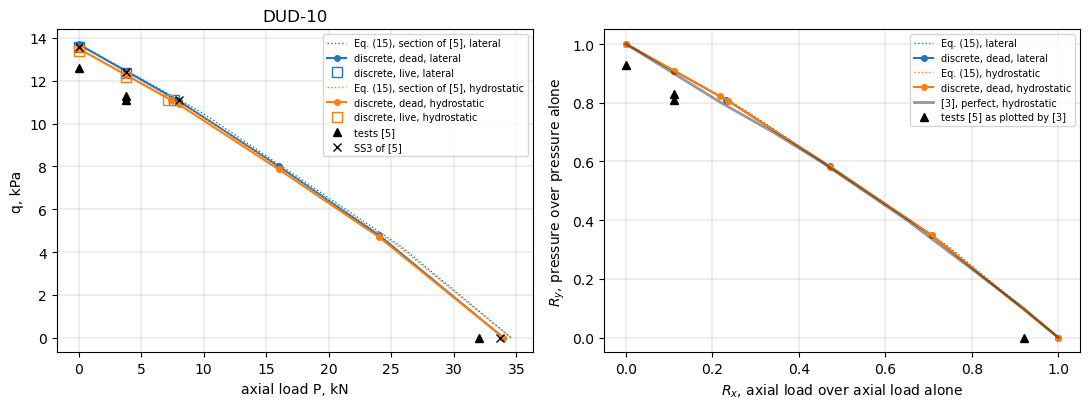

lateral, discrete R_x - Fig. 3(b) at R_y = 0, 0.1, ..., 1: +0.000 -0.004 +0.002 +0.008 +0.006 +0.005 +0.004 +0.009 +0.023 +0.012 +0.000
hydrostatic, discrete R_x - Fig. 3(b) at R_y = 0, 0.1, ..., 1: +0.000 -0.004 +0.002 +0.007 +0.005 +0.004 +0.002 +0.008 +0.023 +0.012 +0.000


In [16]:
# Shen, Zhou and Chen (1993), Fig. 3(b), p. 57, digitized (+-0.02): perfect shell and tests of [5]
SHEN_F3B_RY = np.linspace(0., 1., 11)
SHEN_F3B_RX = np.array([1.00, 0.92, 0.83, 0.74, 0.65, 0.55, 0.45, 0.34, 0.22, 0.11, 0.])
SHEN_F3B_TESTS = np.array([(0.00, 0.92), (0.81, 0.11), (0.83, 0.11), (0.93, 0.00)])
PaxE = kNe*axE['matched'][0]  # discrete, axial compression alone, kN
rows = []
curvesE = {}
for load, hyd in (('lateral', False), ('hydrostatic', True)):
    keys = [(1, 0.), (3, P_RUN3)] + [('P%g' % P_kN, P_kN) for P_kN in (8., 16., 24.)]
    q0 = RESE[(lev, 'matched', 1, load)][0]
    pts = []
    for key, P_kN in keys:
        q, modes = RESE[(lev, 'matched', key, load)][:2]
        pts.append((P_kN, KPA*q))
        sm = su.smeared_ss_pressure(*argsE, *PsecE, de['J'], hyd, P_kN/kNe)
        rows.append([P_kN, load, '%.2f (%d, %d)' % (KPA*q, *modes[0][1:3]), '%.2f' % (KPA*sm[0]),
                     '%+.1f %%' % pct(q, sm[0]), '%.3f' % (P_kN/PaxE), '%.3f' % (q/q0)])
    P2 = kNe*RESE[(lev, 'matched', 2, load)][0]
    pts.append((P2, Q_RUN2))
    rows.append(['%.2f (run 2)' % P2, load, '%.2f' % Q_RUN2, '', '', '%.3f' % (P2/PaxE), '%.3f' % (Q_RUN2/(KPA*q0))])
    curvesE[load] = np.array(sorted(pts) + [(PaxE, 0.)])
table(['P, kN', 'pressure', 'discrete q, kPa (m, n)', 'Eq. (15), same strip', 'gap', 'R_x = P/P_ax',
       'R_y = q/q(P = 0)'], rows)

Ps = np.linspace(0., smE[(4, 'axial')]['W'][0], 60)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for load, hyd, c in (('lateral', False, 'C0'), ('hydrostatic', True, 'C1')):
    qs = np.array([su.smeared_ss_pressure(*argsE, *WsecE, de['J'], hyd, P/kNe)[0] for P in Ps])
    axes[0].plot(Ps, KPA*qs, c + ':', lw=1, label='Eq. (15), section of [5], %s' % load)
    axes[0].plot(curvesE[load][:, 0], curvesE[load][:, 1], c + 'o-', ms=4, label='discrete, dead, %s' % load)
    axes[0].plot([0., P_RUN3, kNe*RESE[(lev, 'live', 2, load)][0]],
                 [KPA*RESE[(lev, 'live', 1, load)][0], KPA*RESE[(lev, 'live', 3, load)][0], Q_RUN2],
                 c + 's', mfc='none', ms=7, label='discrete, live, %s' % load)
    ok = qs > 0
    axes[1].plot(Ps[ok]/Ps[-1], qs[ok]/qs[0], c + ':', lw=1, label='Eq. (15), %s' % load)
    axes[1].plot(curvesE[load][:, 0]/PaxE, curvesE[load][:, 1]/curvesE[load][0, 1], c + 'o-', ms=4,
                 label='discrete, dead, %s' % load)
axes[0].plot([0., DUD10[2][0], P_RUN3, DUD10[4][0]], [DUD10[1][0], Q_RUN2, DUD10[3][0], 0.], 'k^',
             label='tests [5]')
axes[0].plot([0., DUD10[2][1], P_RUN3, DUD10[4][1]], [DUD10[1][1], Q_RUN2, DUD10[3][1], 0.], 'kx',
             label='SS3 of [5]')
axes[0].set_xlabel('axial load P, kN')
axes[0].set_ylabel('q, kPa')
axes[0].set_title('DUD-10')
axes[1].plot(SHEN_F3B_RX, SHEN_F3B_RY, 'k-', lw=2, alpha=0.4, label='[3], perfect, hydrostatic')
axes[1].plot(SHEN_F3B_TESTS[:, 1], SHEN_F3B_TESTS[:, 0], 'k^', label='tests [5] as plotted by [3]')
axes[1].set_xlabel('$R_x$, axial load over axial load alone')
axes[1].set_ylabel('$R_y$, pressure over pressure alone')
for ax in axes:
    ax.grid(True, lw=0.3)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()
for load in ('lateral', 'hydrostatic'):
    cv = curvesE[load]
    Rx = np.interp(SHEN_F3B_RY, cv[::-1, 1]/cv[0, 1], cv[::-1, 0]/PaxE)
    print('%s, discrete R_x - Fig. 3(b) at R_y = 0, 0.1, ..., 1: %s' % (load, ' '.join('%+.3f' % v for v in Rx - SHEN_F3B_RX)))

## Case D of Poorveis and Kabir: combined external pressure and axial compression

Case D of [2] (Table 1, p. 119: $L = 130$ mm, $R = 120.10$ mm, $h = 0.254$
mm, 85 outside stringers, $A_1/(b_1 h) = 0.590$, $e_1/h = 3.420$,
$I_1/(bh^3) = 1.680$, $G_1 J_1/(bD) = 6.563$) is the last shell of Table 1 of
Shen, Zhou and Chen [3] (p. 56: $L$, $R$, $t$, $n_s$, $A_1/(d_1 t) = 0.59$,
$-e_1/t = 3.42$, $I_1/(d_1 t^3) = 1.68$, $G_1 J_1/(d_1 D) = 6.5632$, $E = 7500$
kg/mm$^2$, $\nu = 0.3$), shell AB6 of Singer and Abramovich [6] (Table 1, p. 763: $h = 0.254$ mm,
$L = 130$ mm, $R = 120.1$ mm, $d_1 = 1.485$ mm, $c_1 = 0.9$ mm, $b_1 = 8.9$
mm, $A_1/(b_1 h) = 0.59$, $I_{11}/(b_1 h^3) = 1.68$, $-e_1/h = 3.42$; $d_1$ the height of the stringer,
$e_1$ the distance from the middle surface of the skin to the centroid of
the stringer, $I_{11}$ about its centroidal axis, nomenclature, p. 762), tested
in axial compression on "practical" end rings that simulate a missile clamp
joint (pp. 762-763), with no noticeable load eccentricity (Table 2, footnote
b); [3] calls the ends "close to clamped" (p. 55). The blade of the model, $h_s = \sqrt{12 I_1/A_1} = 1.485$ mm by $t_s =
0.896$ mm on the skin surface (first table), is the rectangle $c_1 \times
d_1$ of [6]. The values for this shell, all in axial compression only:

| quantity | value, kg | $\bar{N}$, kg/mm | source |
|---|---|---|---|
| test $P_{exp}$ (1, 9) | 4025 | 5.334 | [6], Table 2 (p. 764); [3], Table 1 |
| lowest postbuckling load of the test $P_{post}$ | 2250 | 2.982 | same |
| linear smeared theory, SS3 (1, 11) | 3687 | 4.886 | [6], Table 2 |
| linear smeared theory, SS4 (1, 12) | 5425 | 7.189 | [6], Table 2 |
| linear smeared theory, C4 (clamped) (1, 12) | 6489 | 8.599 | [6], Table 2 |
| equivalent end springs of the vibration correlation technique (1, 12) | 5340 | 7.077 | [6], Table 2 |
| perfect shell, boundary-layer theory, $P_{cr}$ (1, 10) | 3918 | 5.192 | [3], Table 1 |
| lowest postbuckling load $P_{low}$ | 2783 | 3.688 | [3], Table 1 |

($\bar{N} = P/(2\pi R)$; 4025 kg is the test 5.334 kg/mm of [2], Table 2;
[6] prints the modes as $n/m$.) [6] defines the "linearity" $\varrho$ as the
test load over the load of the linear theory (nomenclature, p. 762) and gives
for AB6 $\varrho_{SS3} = 1.09$, $\varrho_{SS4} = 0.74$, $\varrho_{C4} = 0.62$
and $\varrho_{sp} = 0.75$ (Table 2). The two ratio columns of Table 1 of [3],
printed 1.09 and 0.62 under the header "$P_{exp}/P_{post}$" with the
sub-headers SS3 and C4 ($4025/2250 = 1.79$), are $\varrho_{SS3}$ and
$\varrho_{C4}$ of [6]: the test over the SS3 and C4 loads of [6] (checked
below). Neither [2] nor [3] gives a
combined-loading or pressure value for this shell: the interaction curves of
[3] (Fig. 3) are those of DUD-8 (case C, previous section) and DUD-10. The
interaction curve of case D is computed here as for case C: equation (15)
for the strip and the section of [2], and the discrete model (whole cylinder,
85 stringers, finest level, matched $J$) under the pressure $q$ at fixed
axial loads $P = 0$, 1000, 2000 and 3000 kg, lateral and hydrostatic, dead
and live. The loads are in kg (kilogram-force) as in [3]; $q$ in
kg/mm$^2$ is printed in kPa, $1$ kg/mm$^2$ = 9806.65 kPa.

1600 s


| case D, lateral, P = 0: level | dofs | pressure | q_cr, kPa (m, n) | change |
|---|---|---|---|---|
| (12, 6, 4) | 23119 | dead | 23.171 (1, 14) |  |
| (16, 8, 4) | 38759 | dead | 23.135 (1, 14) | -0.16 % |
| (20, 10, 5) | 63579 | dead | 23.106 (1, 14) | -0.13 % |
| (16, 8, 4) |  | live | 23.023 |  |
| (20, 10, 5) |  | live | 22.995 | -0.13 % |

| P, kg | pressure | Eq. (15), section of [2], kPa (m, n) | Eq. (15), strip, matched J | discrete, dead (m, n) | gap | discrete, live (m, n) | live vs dead |
|---|---|---|---|---|---|---|---|
| 0 | lateral | 23.28 (1, 14) | 23.29 | 23.11 (1, 14) | **-0.8 %** | 22.99 (1, 14) | -0.48 % |
| 0 | hydrostatic | 22.79 (1, 14) | 22.80 | 22.61 (1, 14) | **-0.8 %** | 22.51 (1, 14) | -0.47 % |
| 1000 | lateral | 18.21 (1, 13) | 18.21 | 17.98 (1, 13) | **-1.2 %** | 17.88 (1, 13) | -0.56 % |
| 1000 | hydrostatic | 17.76 (1, 13) | 17.77 | 17.54 (1, 13) | **-1.3 %** | 17.45 (1, 13) | -0.54 % |
| 2000 | lateral | 12.44 (1, 12) | 12.44 | 12.14 (1, 12) | **-2.4 %** | 12.06 (1, 12) | -0.64 % |
| 2000 | hydrostatic | 12.08 (1, 12) | 12.09 | 11.79 (1, 12) | **-2.5 %** | 11.72 (1, 12) | -0.63 % |
| 3000 | lateral | 5.93 (1, 11) | 5.94 | 5.52 (1, 11) | **-7.1 %** | 5.47 (1, 11) | -0.76 % |
| 3000 | hydrostatic | 5.73 (1, 11) | 5.74 | 5.33 (1, 11) | **-7.1 %** | 5.29 (1, 11) | -0.73 % |

| [6], Table 2 | P, kg | test/P | rho of [6] | ratio of [3], Table 1 |
|---|---|---|---|---|
| SS3 | 3687 | 1.092 | 1.09 | 1.09 |
| SS4 | 5425 | 0.742 | 0.74 | - |
| C4 | 6489 | 0.620 | 0.62 | 0.62 |
| sp | 5340 | 0.754 | 0.75 | - |

| axial compression alone | P, kg | discrete (3719 kg) vs |
|---|---|---|
| test, [6] | 4025 | -7.6 % |
| linear smeared theory, SS3, [6] | 3687 | +0.9 % |
| linear smeared theory, SS4, [6] | 5425 | -31.5 % |
| linear smeared theory, C4 (clamped), [6] | 6489 | -42.7 % |
| equivalent end springs, [6] | 5340 | -30.4 % |
| perfect shell, [3] | 3918 | -5.1 % |
| smeared, nonlinear, [2] | 4052 | -8.2 % |
| discrete, nonlinear, [2] | 4113 | -9.6 % |
| Eq. (15), section of [2] | 3787 | -1.8 % |
| Eq. (15), strip, matched J | 3788 | -1.8 % |

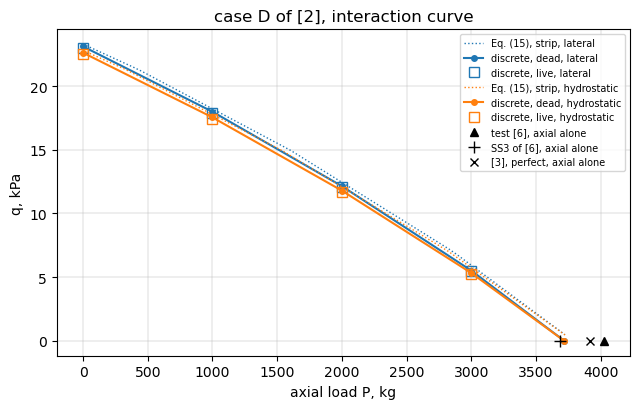

In [17]:
# Shen, Zhou and Chen (1993), Table 1 (p. 56), last row (= case D of [2]), kg
SHEN_D = dict(P_exp=4025., P_post=2250., r_ss3=1.09, r_c4=0.62, P_cr=3918., P_low=2783.)
# Singer and Abramovich (1979) [6], Table 2 (p. 764), shell AB6, kg, and the printed linearities rho
SINGER_AB6 = dict(SS3=(3687., 1.09), SS4=(5425., 0.74), C4=(6489., 0.62), sp=(5340., 0.75))
KPA_D = KGF*1e3  # kPa per kg/mm^2
dd = shells['D']
kgD = 2*np.pi*dd['R']  # kg per unit axial force per unit circumference
PD = (0., 1000., 2000., 3000.)  # kg
argsD = (dd['R'], dd['L'], dd['h'], E, NU, dd['b'])
WsecD = (dd['A'], dd['e'], dd['I'] + dd['A']*dd['e']**2)
PsecD = plate_section(dd)
levD = LEVELS[-1]
t0 = time.time()
RESD = {}
for lv in LEVELS:
    RESD[(lv, 'dead', 0., 'lateral')] = su.buckling_pressure(
        dd['R'], dd['h'], dd['L'], E, NU, dd['ts'], dd['Hs'], 'external', dd['ns'], *lv,
        D66_factor=dd['J']/dd['Jplate'])
for P in PD:
    for load, hyd in (('lateral', False), ('hydrostatic', True)):
        for kind in ('dead', 'live'):
            if (levD, kind, P, load) not in RESD:
                RESD[(levD, kind, P, load)] = su.buckling_pressure(
                    dd['R'], dd['h'], dd['L'], E, NU, dd['ts'], dd['Hs'], 'external', dd['ns'], *levD,
                    D66_factor=dd['J']/dd['Jplate'], hydrostatic=hyd, Nx0=P/kgD, follower=(kind == 'live'))
RESD[(LEVELS[-2], 'live', 0., 'lateral')] = su.buckling_pressure(
    dd['R'], dd['h'], dd['L'], E, NU, dd['ts'], dd['Hs'], 'external', dd['ns'], *LEVELS[-2],
    D66_factor=dd['J']/dd['Jplate'], follower=True)
print('%.0f s' % (time.time() - t0))
rows = []
prev = None
for lv in LEVELS:
    q, modes, md_, skin, ndof = RESD[(lv, 'dead', 0., 'lateral')][:5]
    rows.append([lv, ndof, 'dead', '%.3f (%d, %d)' % (KPA_D*q, *modes[0][1:3]),
                 '' if prev is None else '%+.2f %%' % pct(q, prev)])
    prev = q
q1, q2 = RESD[(LEVELS[-2], 'live', 0., 'lateral')][0], RESD[(levD, 'live', 0., 'lateral')][0]
rows.append([LEVELS[-2], '', 'live', '%.3f' % (KPA_D*q1), ''])
rows.append([levD, '', 'live', '%.3f' % (KPA_D*q2), '%+.2f %%' % pct(q2, q1)])
table(['case D, lateral, P = 0: level', 'dofs', 'pressure', 'q_cr, kPa (m, n)', 'change'], rows)

rows = []
for P in PD:
    for load, hyd in (('lateral', False), ('hydrostatic', True)):
        smS = su.smeared_ss_pressure(*argsD, *PsecD, dd['J'], hyd, P/kgD)
        smW = su.smeared_ss_pressure(*argsD, *WsecD, dd['J'], hyd, P/kgD)
        qd, md_ = RESD[(levD, 'dead', P, load)][:2]
        ql, ml = RESD[(levD, 'live', P, load)][:2]
        rows.append(['%.0f' % P, load, '%.2f %s' % (KPA_D*smW[0], smW[1]), '%.2f' % (KPA_D*smS[0]),
                     '%.2f (%d, %d)' % (KPA_D*qd, *md_[0][1:3]), '**%+.1f %%**' % pct(qd, smS[0]),
                     '%.2f (%d, %d)' % (KPA_D*ql, *ml[0][1:3]), '%+.2f %%' % pct(ql, qd)])
table(['P, kg', 'pressure', 'Eq. (15), section of [2], kPa (m, n)', 'Eq. (15), strip, matched J',
       'discrete, dead (m, n)', 'gap', 'discrete, live (m, n)', 'live vs dead'], rows)

Nd = RES[('D', 'matched')][0]
table(['[6], Table 2', 'P, kg', 'test/P', 'rho of [6]', 'ratio of [3], Table 1'],
      [[k, '%.0f' % P, '%.3f' % (SHEN_D['P_exp']/P), r,
        {'SS3': SHEN_D['r_ss3'], 'C4': SHEN_D['r_c4']}.get(k, '-')] for k, (P, r) in SINGER_AB6.items()])
ax_refs = [('test, [6]', SHEN_D['P_exp']),
           ('linear smeared theory, SS3, [6]', SINGER_AB6['SS3'][0]),
           ('linear smeared theory, SS4, [6]', SINGER_AB6['SS4'][0]),
           ('linear smeared theory, C4 (clamped), [6]', SINGER_AB6['C4'][0]),
           ('equivalent end springs, [6]', SINGER_AB6['sp'][0]),
           ('perfect shell, [3]', SHEN_D['P_cr']),
           ('smeared, nonlinear, [2]', kgD*POORVEIS_T2['D'][1]),
           ('discrete, nonlinear, [2]', kgD*POORVEIS_T2['D'][2]),
           ('Eq. (15), section of [2]', kgD*shells['D']['sm_W'][0]),
           ('Eq. (15), strip, matched J', kgD*shells['D']['sm']['matched'][0])]
table(['axial compression alone', 'P, kg', 'discrete (%.0f kg) vs' % (kgD*Nd)],
      [[name, '%.0f' % P, '%+.1f %%' % pct(kgD*Nd, P)] for name, P in ax_refs])

fig, ax = plt.subplots(figsize=(6.5, 4.2))
Ps = np.linspace(0., kgD*shells['D']['sm']['matched'][0], 60)
for load, hyd, c in (('lateral', False, 'C0'), ('hydrostatic', True, 'C1')):
    qs = np.array([su.smeared_ss_pressure(*argsD, *PsecD, dd['J'], hyd, P/kgD)[0] for P in Ps])
    ok = qs > 0
    ax.plot(Ps[ok], KPA_D*qs[ok], c + ':', lw=1, label='Eq. (15), strip, %s' % load)
    ax.plot(list(PD) + [kgD*Nd], [KPA_D*RESD[(levD, 'dead', P, load)][0] for P in PD] + [0.], c + 'o-', ms=4,
            label='discrete, dead, %s' % load)
    ax.plot(PD, [KPA_D*RESD[(levD, 'live', P, load)][0] for P in PD], c + 's', mfc='none', ms=7,
            label='discrete, live, %s' % load)
ax.plot([SHEN_D['P_exp']], [0.], 'k^', label='test [6], axial alone')
ax.plot([SINGER_AB6['SS3'][0]], [0.], 'k+', ms=9, label='SS3 of [6], axial alone')
ax.plot([SHEN_D['P_cr']], [0.], 'kx', label='[3], perfect, axial alone')
ax.set_xlabel('axial load P, kg')
ax.set_ylabel('q, kPa')
ax.set_title('case D of [2], interaction curve')
ax.grid(True, lw=0.3)
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

**Case B** of [2] is cylinder 1 of Card and Jones (1966),
`card1966_blade_cylinder_buckling.ipynb`; case C is in the previous
section.

## Discussion

- **Input.** Equation (15) of [4] with the stringer properties of Table 1 of
  [1] reproduces the SS3 loads of [1] within 0.14 % for the five shells, so
  the section, the material and the number of stringers are read as Weller
  and Singer read them. The stringers are rectangles on the skin surface;
  their torsion constant $I_{t1}$ is that of the rectangle. The blade of the
  model is this rectangle, so that equation (15) for the strip with the
  matched $J$ is within 0.05 % of equation (15) for the section of [1].
- **General instability (AS-34, AS-35, case D; $\theta = 0.47$, $b/\sqrt{Rh}
  = 1.6$).** The discrete model buckles in the general mode $(m, n) = (1,
  11)$ of the smeared theory, 1.6 % (AS-34) and 1.7 % (AS-35) below equation
  (15) for the same plate strip with the matched twisting stiffness (2.8 and
  2.9 % with the plate twisting stiffness; case D 1.8 and 2.7 %). This is the
  discreteness gap at this spacing: one to two percent. Against the SS3 loads
  of [1], for the same rectangle, the discrete model is 1.8 % below. The tests
  are at 82 and 84 % of SS3 (the "linearity" of [1]), +20 and +17 % from the
  discrete model: the
  difference between test and theory is the imperfection sensitivity
  discussed in [1], not the discreteness of the stringers.
- **Panel instability (AS-27; $\theta = 0.79$ to 0.81).** The lowest mode of
  the discrete model is local: the skin between the stringers buckles with
  one half-wave per bay ($n = n_s/2 = 28$) and nine axial half-waves, at
  4.00 to 4.39 kg/mm, 21.0 to 27.8 % below the general instability of the smeared
  theory, which cannot represent this mode. This is the case of a large
  "gap" in the literature: Poorveis and Kabir found their discrete value 30 %
  below their smeared one for AS-27M2 and attributed it to panel instability
  ([2], p. 119). The discrete model of this notebook is +0.8 % from the
  test of AS-27M2 and +3.3 % from the discrete value of [2] (whose model
  includes the nonlinear pre-buckling deformation and transverse shear); the
  three tests of the nearly equal AS-27 shells scatter from 4.36 to 5.17
  kg/mm, and the model is -15.8, +0.8 and -16.8 % from them. The local load is almost
  independent of the twisting stiffness of the stringers (+0.9 to +1.0 % from
  matched to plate $J$), whereas the general-instability load of the smeared
  theory rises by 40 % with the plate twisting stiffness: with an unmatched
  plate strip the apparent gap would be 43 to 48 %. In the model the skin
  bay is the whole pitch $b = 13.5$ mm, the stringer root being a line; the
  real stringers are 1.53 mm wide (11 % of the pitch), which leaves a
  narrower skin panel and would raise the local load (a plate-buckling load
  scales with the inverse square of the panel width: $(13.53/12.0)^2 = 1.27$
  for the free width, an estimate, not a computed value).
- **Case D of [2]** (85 stringers, from Shen, Zhou and Chen [3]): discrete
  4.928 kg/mm, -1.8 % from equation (15) for the same strip, -7.6 %
  from the test of shell AB6 of Singer and Abramovich [6], cited by [3]
  and [2]. Poorveis and Kabir give the discrete
  value 1.5 % *above* the smeared one (5.450 and 5.370 kg/mm); their smeared
  nonlinear value is 7 % above equation (15) with their own section (5.018
  kg/mm), so the difference between their two models and the linear theory
  is larger than the discreteness effect found here. Case B of [2] (cylinder
  1 of Card and Jones, discrete 5.2 % above smeared in [2]): both
  implementations of the card1966 notebooks give the discrete simply
  supported membrane load within 0.1 % of the smeared $\bar{N}_s$.
- **Case C of [2] (shell DUD-8 of [5], external pressure; $\theta =
  0.48$).** Every loading buckles in the general mode $(m, n) = (1, 11)$ of
  the smeared theory (the tests: $n = 10$ and 9), and the discrete model is
  within 0.6 % of equation (15) for the same strip (matched $J$; 1.1 % with
  the plate $J$): the stringers carry no hoop force, so the pressure part of
  the buckling load has no discreteness gap at this spacing, whereas the
  axial run 4 of the same shell gives -1.8 %, as AS-34 and AS-35. With the
  section of [2], equation (15) is within 0.6 to 0.8 % (lateral) and -0.7 to
  -0.9 % (hydrostatic) of the SS3 predictions of [5] (+2.7 % for run 4), so
  these do not tell which pressure [5] computed; the end load of hydrostatic
  pressure lowers $q$ by 1.5 %. The discrete model (matched $J$) is -1.4,
  -2.1 and -3.4 % (lateral) or -2.8, -3.5 and -4.8 % (hydrostatic) from the
  tests of runs 1 to 3 (13.55, 12.3, 11.10 kPa) and +4.5 % from the axial
  test. The tests are at 1.02 to 1.04 of the SS3 predictions of [5] (Table
  4), whereas the actual ends, between SS3 and SS4, give 14.6, 14.2 and 13.3
  kPa with the equivalent springs of [5]: the agreement of the SS3 model with
  the tests is a balance of a stiffer end restraint against imperfections,
  not a check of the model. The twisting stiffness enters directly: the plate
  $J$ raises $q$ by 4.9 % (run 1) to 6.2 % (run 3). The nonlinear values of [2] bracket the tests:
  smeared -2.9 and -1.4 %, discrete +9.2 and +14.4 %, the discrete 12.5 and
  16.0 % above the smeared, whereas here discrete and smeared agree; the
  discrete model here is 9.7 to 16.8 % below the discrete values of [2].
- **Live pressure (case C).** The load stiffness of the follower pressure
  is symmetric here, its skew part being $8 \times 10^{-11}$ of its norm after the reduction (ends with $w = 0$, symmetry planes $v = 0$, panels connected to each other), as the condition of
  Hibbitt (1979) and Schweizerhof and Ramm (1984, Table 2) says for a
  uniform pressure on a surface whose edges have $w = 0$ or a zero normal
  displacement; the unsymmetric solver returns the same real eigenvalues.
  The live pressure lowers $q$ by 0.78 to 0.79 % for every run, lateral and
  hydrostatic, in the same mode $(m, n) = (1, 11)$: runs 1 to 3 13.26, 11.95, 10.64 kPa
  (lateral) and 13.07, 11.77, 10.48 kPa (hydrostatic), -2.1, -2.9 and -4.2 % (lateral) or -3.6, -4.3 and -5.6 % (hydrostatic) from the tests. The live
  lateral values are within 0.6 % of the SS3 predictions of [5], the live
  hydrostatic ones -1.8 to -2.0 %. Neither [2] nor [5] says which of the four
  variants it computed; they span 2.3 %, less than the effect of the end
  restraint (the equivalent springs of [5] give 10 to 24 % more than SS3).
- **Interaction curve of DUD-8.** Up to $P = 8$ kN the discrete model
  follows equation (15) for the same strip within 0.6 %; at $P = 16$ and 24
  kN (7.71 and 4.50 kPa lateral, 7.57 and 4.42 kPa hydrostatic), where the mode becomes $(1, 10)$, the gap is -1.3 and -3.6 %, against
  -1.8 % under axial compression alone. Divided by its own values under
  pressure alone and axial load alone, the discrete curve lies on the
  perfect-shell curve of Shen, Zhou and Chen [3] (Fig. 3(a)) within 0.011
  in $R_x$, about the reading precision (0.01), slightly outside the straight line $R_x + R_y =
  1$, and so does equation (15): the shape of the interaction curve of this
  shell is the same in the linear smeared theory, the discrete model and the
  boundary-layer theory of [3]. The tests of [5], as plotted by [3], lie on
  the curves, except the axial test ($R_x = 0.93$).
- **Case D under combined loading.** Neither [2] nor [3] gives a pressure or
  combined-loading value for this shell; the interaction curve here is a
  prediction. Under pressure alone the discrete model buckles in $(1, 14)$;
  at $P = 0$, 1000, 2000 and 3000 kg (dead pressure) 23.11, 17.98, 12.14 and 5.52 kPa lateral and
  22.61, 17.54, 11.79 and 5.33 kPa hydrostatic, the mode going to $n = 13$, 12 and 11 and the gap
  against equation (15) for the same strip -0.8, -1.2 to -1.3, -2.4 to -2.5 and -7.1 % as the axial share grows
  (axial compression alone -1.8 %); the live pressure lowers $q$ by 0.47 to
  0.76 %. Axial compression alone, 3719 kg: -7.6 % from the test of [6] (4025
  kg), -5.1 % from the perfect shell of [3] (3918 kg), +0.9 % from the SS3
  load of the linear smeared theory of [6] (3687 kg; equation (15) with the
  section of [2] gives 3787 kg) and -9.6 % from the discrete value of [2].
  [6] gives 5425 kg for SS4, 6489 kg for clamped C4 ends (76 % above SS3)
  and 5340 kg with the equivalent end springs of its vibration correlation
  technique, 1.6 % below SS4: [3] calls the ends "close to clamped" (p.
  55), the vibrations of [6] place them near SS4, and the test is at 0.75
  of that load. The ratio columns of Table 1 of [3] are $\varrho_{SS3}$
  and $\varrho_{C4}$ of [6] (4025/3687 = 1.092, 4025/6489 = 0.620).
- **Shell DUD-10 of [5] (twin of DUD-8, combined loading in the reversed
  sequence; $\theta = 0.47$).** The data of Table 1 of [5] are consistent
  ($R = 120.12$ mm from $L/R$ and $b_1$; the rectangle $c_1 \times d_1$
  reproduces area, moment of inertia and eccentricity within 0.1 %); the
  torsion constant, not printed, is that of the rectangle ($G J/(bD) =
  7.32$; for DUD-8 the rectangle is +0.7 % from $G_1 J_1/(bD)$ of [2]).
  Equation (15) with this section reproduces the SS3 predictions of [5]
  (Table 5) with lateral pressure within 0.7 to 0.9 % for runs 1 to 3 (13.72
  kPa, 8.07 kN, 12.48 kPa against 13.6, 7.99, 12.4), and with hydrostatic
  pressure within -0.6 and -0.8 % for runs 1 and 3 but -5.4 % for run 2
  (7.56 kN): run 2, at a fixed pressure, separates the two, and the SS3
  values of [5] are those of lateral pressure; run 4, +2.7 % (34.58 kN
  against 33.66 kN), as for DUD-8. The discrete model (matched $J$, converged
  to 0.06 %) buckles in $(m, n) = (1, 11)$ under pressure, $(1, 9)$ in axial
  compression, as the SS3 predictions of [5] (the tests: $n = 10$, 9, 9, 7),
  with the gap -0.1 % (run 1), -0.3 % (run 3), -2.3 and -2.4 % (run 2, in
  $P$) and -1.8 % (run 4): runs 1 to 4 13.70, 7.88, 12.45 kPa or kN lateral,
  13.50, 7.38, 12.26 hydrostatic, 33.97 kN axial. Against the tests the model
  is +8.8, +10.2 % (lateral) and +7.2, +8.5 % (hydrostatic) for runs 1 and 3
  and +6.1 % for run 4, whereas the test of run 2, 3.80 kN, is half of every
  prediction ($\varrho_{SS3} = 0.48$ in [5]). Holding the pressure near its
  critical value amplifies any deficit: along the interaction curve
  $dP/dq \approx -3$ kN/kPa, so 1 % less pressure capacity (0.14 kPa) costs
  about 0.4 kN of $P$, 5 % of the 8 kN; the line through the tests of runs 1
  and 3 (12.6 kPa at $P = 0$, 11.3 kPa at 3.8 kN) reaches 11.1 kPa at 4.4 kN.
  The live pressure lowers $q$ by 0.78 to 0.79 % (runs 1 and 3; live
  lateral within 0.4 % of the SS3 of [5]) and $P$ of run 2 by 3.41 % (lateral,
  7.61 kN) and 3.65 % (hydrostatic, 7.11 kN). The twisting stiffness enters as
  for DUD-8: the plate $J$ raises $q$ by 4.8 to 5.3 % and $P$ of run 4 by 3.9 %; in
  equation (15), $J = 0$ lowers run 1 by 12 % and run 2 from 8.07 to 2.98 kN,
  so run 2 is also the run most sensitive to the torsion constant that [5]
  does not print; $R = 119.95$ mm changes equation (15) by 0.3 % or less (1.1
  to 1.3 % for run 2). Divided by its own pure-load values the discrete curve
  (hydrostatic or lateral) lies on the perfect-shell curve of Fig. 3(b) of
  [3] within 0.012, and 0.023 at $R_y = 0.8$, about the reading precision
  (0.02); the tests of [5] as plotted by [3] are shown as read.
- **Summary of the gap.** With closely spaced stringers that buckle in a
  general mode, the discrete model is 1 to 2 % below the smeared theory of
  the same section; when the skin between the stringers is prone to panel
  buckling ($\theta > 0.64$), the discrete model buckles locally, 21 to 28 %
  below the smeared general instability. Weller and Singer write that the
  discreteness "has also been studied and found to be negligible for closely
  spaced stiffened cylinders except for unusual geometries" (p. 722); the
  AS-27 shells are such a geometry by design.
- **The bfsccylinder implementation of this case**
  (`bfsccylinder/notebooks/weller1977_stiffened_cylinder_buckling.ipynb`:
  one stringer pitch with cyclic symmetry, `BFSCCylinderSanders` skin and
  `BFSCPlate2D` stringer, every harmonic $n \le n_s/2$, the same $J$) takes
  the stringer plate from the middle surface of the skin, $H_s = h_s + h/2$,
  overlapping half the skin thickness, where the blade here starts at the
  skin surface (the rectangle of [1]); its stringer has the larger area and
  radial bending stiffness. It gives the same modes, and its loads are 1.2 %
  higher in the general modes and 3.3 to 3.4 % higher in the local modes of
  the AS-27 shells: AS-27M1/M2/M3 4.134, 4.540, 4.453 kg/mm (here 4.001,
  4.390, 4.307); AS-34 and AS-35 4.526 and 4.470 (here 4.471 and 4.416);
  case D 4.988 (here 4.928). Its gaps, against equation (15) for its own
  strip, are -1.2 % (AS-34, AS-35) and -1.3 % (case D) with the matched $J$.
  It also checks that the rectangle $t_s \times h_s$ reproduces $e_1$ and
  $I_{t1}$ of [1]. Case C (external pressure, sector of one stringer pitch,
  every harmonic $n \le 42$, 49 x 16 x 5 mesh): runs 1 to 3 13.47, 12.15,
  10.83 kPa lateral and 13.27, 11.97, 10.67 kPa hydrostatic (here 13.37,
  12.04, 10.72 and 13.17, 11.87, 10.56; 0.8 to 1.0 % apart), gaps +0.0 to
  +0.4 % (here -0.1 to -0.6 %); run 4 33.84 kN (here 33.45 kN). Live
  pressure (case C): 13.36, 12.05, 10.74 kPa lateral and 13.17, 11.88, 10.58
  kPa hydrostatic (here 13.26, 11.95, 10.64 and 13.07, 11.77, 10.48), the
  same -0.78 to -0.79 % from the dead pressure; $P = 16$ and 24 kN: 7.85 and
  4.64 kPa lateral, 7.71 and 4.55 kPa hydrostatic (here 7.71, 4.50, 7.57,
  4.42; 1.8 to 3.1 % apart). Case D under combined loading, lateral, $P = 0$
  to 3000 kg: dead 23.31, 18.21, 12.42, 5.86 kPa, live 23.19, 18.11, 12.34,
  5.82 kPa (here 23.11, 17.98, 12.14, 5.52 and 22.99, 17.88, 12.06, 5.47):
  0.9 to 2.3 % apart up to 2000 kg and 6.2 to 6.4 % at 3000 kg, where its gap
  is -4.2 % (here -7.1 %), as for the axial load alone (-1.3 %, here -1.8 %).
  DUD-10 (sector, every harmonic, 49 x 16 x 5 mesh, matched $J$): runs 1
  to 4 13.81, 8.20, 12.55 kPa or kN lateral and 13.61, 7.70, 12.37
  hydrostatic, 34.37 kN axial (here 13.70, 7.88, 12.45, 13.50, 7.38, 12.26
  and 33.97), gaps +0.2 to +0.4 % under pressure, 0.0 % in $P$ of run 2 and
  -1.3 % axial (here -0.1 to -0.3 %, -2.3 to -2.4 % and -1.8 %): the 0.8
  to 0.9 % between the two pressures becomes 4.1 to 4.3 % in $P$ of run 2;
  live pressure -0.78 to -0.79 % in $q$ and -3.3 to -3.5 % in $P$ of run 2
  (here -3.41 and -3.65 %); its normalized curve lies on Fig. 3(b) of [3]
  within 0.012, 0.023 at $R_y = 0.8$ (here the same).